# Geometric versus electronic contributions to the band gap of ABX3 halide perovskites

Computational notebook for the B.Tech project (DTU, Engineering Physics). It runs from top to bottom
(`Runtime > Run all` on Google Colab, or `jupyter nbconvert --execute` locally).

Data: halide perovskite dataset of Yang, Manganaris and Mannodi-Kanakkithodi (Digital Discovery 2023, CC-BY),
file `perovs_data_final.xlsx` from the GitHub repository `yjq829/perovskite_dataset`.

Notes for the reader:
* Every number printed here is computed from the data in this notebook. Numbers are also collected in `numbers.json`.
* Figures go to `figures/`, tables to `tables/`.
* Mixed compounds are described by composition-weighted averages of the site properties. This is a simplification.

## Stage 0: setup, data and checks

Question: is the dataset complete and parsed correctly, and do our recomputed geometric factors match the dataset?
We download the file if needed, merge the four levels of theory, parse every formula and check the known facts.

In [1]:
# Install missing packages (needed on Colab; skipped when the package is already installed).
import importlib
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pymatgen": "pymatgen",
    "scikit-learn": "sklearn",
    "pandas": "pandas",
    "openpyxl": "openpyxl",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "scipy": "scipy",
}
for pip_name, module_name in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        print("Installing", pip_name)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

In [2]:
import json
import re
import shutil
import tempfile
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import pymatgen.core
from pymatgen.core import Element

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

NOTEBOOK_START_TIME = time.time()
print("python", sys.version.split()[0])
for module in [np, pd, matplotlib, scipy, sklearn, pymatgen.core]:
    print(module.__name__, getattr(module, "__version__", "?"))

python 3.13.18
numpy 2.5.3
pandas 3.0.5
matplotlib 3.11.2
scipy 1.18.1
sklearn 1.9.1
pymatgen.core 2026.10.31


In [3]:
# ---------------- CONFIGURATION (all paths and fixed choices in one place) ----------------
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "perovs_data_final.xlsx"
FIG_DIR = PROJECT_DIR / "figures"
TABLE_DIR = PROJECT_DIR / "tables"
EXPERIMENT_PATH = PROJECT_DIR / "experimental" / "experimental_verified.csv"
EXPERIMENT_TEMPLATE_PATH = PROJECT_DIR / "experimental_template.csv"
NUMBERS_PATH = PROJECT_DIR / "numbers.json"
DATASET_REPO_URL = "https://github.com/yjq829/perovskite_dataset.git"

RANDOM_STATE = 0
N_BOOTSTRAP = 500

FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

# Ionic radii in angstrom. Only ONE set is given ("dataset": recovered exactly from the dataset's own
# tolerance and octahedral factor columns). A second set can be added here later for the robustness test
# (stage 8); the key of the active set is ACTIVE_RADII.
RADII_SETS = {
    "dataset": {
        "A": {"K": 1.51, "Rb": 1.61, "Cs": 1.74, "Ma": 2.17, "Fa": 2.53},
        "B": {"Ge": 0.87, "Ca": 1.00, "Sn": 1.15, "Pb": 1.19, "Sr": 1.26, "Ba": 1.42},
        "X": {"Cl": 1.81, "Br": 1.96, "I": 2.20},
    },
}
ACTIVE_RADII = "dataset"

# Site elements. "Ma" and "Fa" stand for methylammonium (MA) and formamidinium (FA) after formula parsing.
A_ELEMENTS = ["Cs", "K", "Rb", "Ma", "Fa"]
B_ELEMENTS = ["Ge", "Sn", "Pb", "Ca", "Sr", "Ba"]
X_ELEMENTS = ["Cl", "Br", "I"]
GROUP14_B = ["Ge", "Sn", "Pb"]
GROUP2_B = ["Ca", "Sr", "Ba"]
ORGANIC_A = ["Ma", "Fa"]

# Atomic numbers (used as descriptors Z_B and Z_X)
Z_NUMBER = {"Ge": 32, "Sn": 50, "Pb": 82, "Ca": 20, "Sr": 38, "Ba": 56, "Cl": 17, "Br": 35, "I": 53}

# Levels of theory: sheet name -> column name used in this notebook
LEVELS = ["PBE", "HSErel", "HSErel_SOC", "HSE-PBE-SOC"]
GAP_COL = {
    "PBE": "gap_PBE",
    "HSErel": "gap_HSErel",
    "HSErel_SOC": "gap_HSErel_SOC",
    "HSE-PBE-SOC": "gap_HSE_PBE_SOC",
}
# Pretty labels for plots
A_LABEL = {"Cs": "Cs", "K": "K", "Rb": "Rb", "Ma": "MA", "Fa": "FA"}

In [4]:
# ---------------- PLOT STYLE AND COLOURS ----------------
# One colour per meaning, never reused for another meaning (checked by the assert below).
# Base palettes: Okabe-Ito (B elements) and Paul Tol palettes (colour-blind safe).
COLOR_B = {"Ge": "#E69F00", "Sn": "#56B4E9", "Pb": "#009E73",
           "Ca": "#D55E00", "Sr": "#CC79A7", "Ba": "#0072B2"}
COLOR_GROUP = {"Group 14": "#332288", "mixed B": "#BBBBBB", "Group 2": "#882255"}
COLOR_ATYPE = {"inorganic A": "#000000", "organic A": "#DDCC77", "mixed organic/inorganic A": "#44AA99"}
COLOR_LEVEL = {"PBE": "#77AADD", "HSErel": "#EE8866", "HSErel_SOC": "#AAAA00", "HSE-PBE-SOC": "#994455"}
COLOR_MODEL = {"mean baseline": "#777777", "RandomForest": "#117733", "Ridge": "#AA4499", "Linear": "#4477AA"}
COLOR_CV = {"random KFold": "#EECC66", "GroupKFold": "#004488"}
MARKER_ATYPE = {"inorganic A": "o", "organic A": "^", "mixed organic/inorganic A": "s"}

all_colours = []
for palette in [COLOR_B, COLOR_GROUP, COLOR_ATYPE, COLOR_LEVEL, COLOR_MODEL, COLOR_CV]:
    all_colours = all_colours + list(palette.values())
assert len(all_colours) == len(set(all_colours)), "a colour is used for two meanings"

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 7.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
warnings.filterwarnings("ignore", category=FutureWarning)

In [5]:
# ---------------- SMALL HELPER FUNCTIONS (defined once, used everywhere) ----------------
NUMBERS = {}


def to_plain(value):
    """Turn numpy numbers into plain Python numbers (for JSON)."""
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        if np.isnan(value):
            return None
        return round(float(value), 4)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    return value


def record(name, value, stage, note=""):
    """Store a reported number with the stage that produced it (written to numbers.json)."""
    NUMBERS[name] = {"value": to_plain(value), "stage": stage, "note": note}


def write_numbers():
    with open(NUMBERS_PATH, "w") as handle:
        json.dump(NUMBERS, handle, indent=1)
    print("numbers.json now holds", len(NUMBERS), "numbers")


def save_fig(fig, name):
    """Save a figure at 300 dpi to figures/ and show it."""
    path = FIG_DIR / (name + ".png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("saved", path.name)
    plt.show()
    plt.close(fig)


def save_table(table, name, index=False):
    path = TABLE_DIR / (name + ".csv")
    table.to_csv(path, index=index)
    print("saved table", path.name, "shape", table.shape)


def panel_label(ax, text):
    """Put the panel letter in front of the title, e.g. '(a) title'. Call it after ax.set_title."""
    title = ax.get_title()
    if title:
        ax.set_title("(" + text + ") " + title)
    else:
        ax.set_title("(" + text + ")", loc="left", fontweight="bold")


def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def eta_squared(values, labels):
    """Fraction of the variance of `values` explained by the category `labels` (one-way ANOVA eta squared)."""
    values = pd.Series(np.asarray(values, dtype=float))
    labels = pd.Series(np.asarray(labels))
    total_ss = ((values - values.mean()) ** 2).sum()
    group_means = values.groupby(labels).transform("mean")
    within_ss = ((values - group_means) ** 2).sum()
    return float(1.0 - within_ss / total_ss)


def make_model(name, seed=RANDOM_STATE):
    """The three model types used in stage 5 (and later)."""
    if name == "mean baseline":
        return DummyRegressor(strategy="mean")
    if name == "RandomForest":
        return RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1)
    if name == "Ridge":
        return Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=1.0))])
    if name == "Linear":
        return LinearRegression()
    raise ValueError(name)


def cv_predict(model, X, y, splitter, groups=None):
    """Out-of-fold predictions. Each row is predicted by a model that did not see it."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    predictions = np.full(len(y), np.nan)
    fold_r2 = []
    if isinstance(splitter, GroupKFold):
        splits = splitter.split(X, y, groups)
    else:
        splits = splitter.split(X, y)
    for train_index, test_index in splits:
        fitted = clone(model).fit(X[train_index], y[train_index])
        predictions[test_index] = fitted.predict(X[test_index])
        fold_r2.append(r2_score(y[test_index], predictions[test_index]))
    return predictions, fold_r2


def cv_scores(model, X, y, splitter, groups=None):
    """R2 (pooled out-of-fold), mean per-fold R2 and MAE for one model and one splitter."""
    predictions, fold_r2 = cv_predict(model, X, y, splitter, groups)
    return {"R2": r2_score(y, predictions), "R2_fold_mean": float(np.mean(fold_r2)),
            "MAE": mae(y, predictions), "predictions": predictions}

print("helpers ready")

helpers ready


### Stage 0a: get the data file
If `data/perovs_data_final.xlsx` is missing, the dataset repository is cloned into a temporary folder and the file is
copied. If that fails, the notebook stops: no data is ever created or guessed.

In [6]:
if DATA_PATH.exists():
    print("Data file found:", DATA_PATH)
else:
    DATA_PATH.parent.mkdir(exist_ok=True)
    temp_folder = Path(tempfile.mkdtemp())
    print("Cloning", DATASET_REPO_URL, "into", temp_folder)
    result = subprocess.run(["git", "clone", "--depth", "1", DATASET_REPO_URL, str(temp_folder / "repo")],
                            capture_output=True, text=True)
    print(result.stdout, result.stderr)
    found_files = list((temp_folder / "repo").rglob("perovs_data_final.xlsx"))
    if len(found_files) == 0:
        raise RuntimeError("Could not obtain perovs_data_final.xlsx. Please upload it to data/. "
                           "No data has been created or simulated.")
    shutil.copy(found_files[0], DATA_PATH)
    print("Copied", found_files[0], "to", DATA_PATH)

Data file found: /home/user/BTP-Perovskite/data/perovs_data_final.xlsx


### Stage 0b: load the four sheets and merge them on Formula (outer merge)

In [7]:
raw_sheets = pd.read_excel(DATA_PATH, sheet_name=None)
print("Sheets:", list(raw_sheets.keys()))
for sheet_name, sheet in raw_sheets.items():
    print(sheet_name, sheet.shape)
print("\nPBE columns:", list(raw_sheets["PBE"].columns))

# Find the deviation-of-cubicity columns by searching for "Deviation"
pbe_sheet = raw_sheets["PBE"]
DEVIATION_COLS_RAW = [c for c in pbe_sheet.columns if "Deviation" in c]
print("Deviation columns:", DEVIATION_COLS_RAW)
DEVIATION_RENAME = {
    "Deviation of Cubicity b axis": "dev_b",
    "Deviation of Cubicity c axis": "dev_c",
    "Deviation of Cubicity at alpha": "dev_alpha",
    "Deviation of Cubicity at beta": "dev_beta",
    "Deviation of Cubicity at gamma": "dev_gamma",
}
assert set(DEVIATION_RENAME) == set(DEVIATION_COLS_RAW)
DEV_COLS = list(DEVIATION_RENAME.values())

Sheets: ['PBE', 'HSErel', 'HSErel_SOC', 'HSE-PBE-SOC']
PBE (488, 12)
HSErel (299, 4)
HSErel_SOC (282, 4)
HSE-PBE-SOC (244, 4)

PBE columns: ['Formula', 'Decomposition Energy (eV p.f.u.)', 'Band Gap (eV)', 'SLME @ 5um', 'Deviation of Cubicity b axis', 'Deviation of Cubicity c axis', 'Deviation of Cubicity at alpha', 'Deviation of Cubicity at beta', 'Deviation of Cubicity at gamma', 'Octaehdral Factor', 'Tolerance Factor', "Bartel's Tolerance Factor"]
Deviation columns: ['Deviation of Cubicity b axis', 'Deviation of Cubicity c axis', 'Deviation of Cubicity at alpha', 'Deviation of Cubicity at beta', 'Deviation of Cubicity at gamma']


In [8]:
# Start from the list of all formulas, then add one gap column per level of theory.
master = pd.DataFrame({"Formula": pd.concat([s["Formula"] for s in raw_sheets.values()]).unique()})
for level in LEVELS:
    sheet = raw_sheets[level]
    assert sheet["Formula"].duplicated().sum() == 0, "duplicated formula in " + level
    gaps = sheet[["Formula", "Band Gap (eV)"]].rename(columns={"Band Gap (eV)": GAP_COL[level]})
    master = master.merge(gaps, on="Formula", how="outer")

# Extra PBE columns: deviation of cubicity, dataset octahedral/tolerance factor, dataset "Bartel" column
pbe_extra = pbe_sheet[["Formula"] + DEVIATION_COLS_RAW + ["Octaehdral Factor", "Tolerance Factor",
                                                          "Bartel's Tolerance Factor"]]
pbe_extra = pbe_extra.rename(columns=DEVIATION_RENAME)
pbe_extra = pbe_extra.rename(columns={"Octaehdral Factor": "dataset_octahedral",
                                      "Tolerance Factor": "dataset_tolerance",
                                      "Bartel's Tolerance Factor": "dataset_bartel_column"})
master = master.merge(pbe_extra, on="Formula", how="left")
master = master.sort_values("Formula").reset_index(drop=True)
print(master.shape)
master.head()

(490, 13)


,Formula,gap_PBE,gap_HSErel,gap_HSErel_SOC,gap_HSE_PBE_SOC,dev_b,dev_c,dev_alpha,dev_beta,dev_gamma,dataset_octahedral,dataset_tolerance,dataset_bartel_column
0,CsBaBr_1.125Cl_1.875,4.187,NaN,NaN,NaN,6.694269e-03,1.478023e-02,5.034304e-04,0.000044,4.532193e-07,0.760884,0.775962,6.029438
1,CsBaBr_3,3.996,5.1203,5.0142,5.0142,1.500929e-07,1.500929e-07,0.000000e+00,0.000000,0.000000e+00,0.724490,0.774052,6.029438
2,CsBaCl_3,4.667,5.9307,5.9059,5.9059,4.737084e-07,4.737084e-07,0.000000e+00,0.000000,0.000000e+00,0.784530,0.777161,6.029438
3,CsBaI_0.375_Cl_2.625,4.067,NaN,NaN,NaN,3.971800e-02,1.917515e-02,2.027437e-07,0.000282,1.887523e-06,0.763954,0.776119,6.029438
4,CsBaI_0.75_Cl_2.25,3.897,NaN,NaN,NaN,3.830729e-02,4.811735e-03,8.240648e-03,0.003483,5.705933e-03,0.744430,0.775108,6.029438


### Stage 0c: parse formulas
"MA" becomes "Ma" and "FA" becomes "Fa", then the regex `([A-Z][a-z]?)(?:_([0-9.]+))?` gives element counts
(a missing count means 1). Halide fraction = halide count / 3.

In [9]:
FORMULA_PATTERN = re.compile(r"([A-Z][a-z]?)(?:_([0-9.]+))?")
KNOWN_ELEMENTS = A_ELEMENTS + B_ELEMENTS + X_ELEMENTS


def parse_formula(formula):
    """Return a dictionary element -> count for one dataset formula, e.g. 'CsPbI_3' -> {Cs:1, Pb:1, I:3}."""
    text = formula.replace("MA", "Ma").replace("FA", "Fa")
    counts = {}
    for element, number in FORMULA_PATTERN.findall(text):
        if element not in KNOWN_ELEMENTS:
            raise ValueError("unknown element " + element + " in " + formula)
        if number == "":
            amount = 1.0
        else:
            amount = float(number)
        counts[element] = counts.get(element, 0.0) + amount
    return counts


parse_errors = []
parsed_rows = []
for formula in master["Formula"]:
    try:
        parsed_rows.append(parse_formula(formula))
    except ValueError as error:
        parse_errors.append(str(error))
        parsed_rows.append({})
print("parse errors:", len(parse_errors))
assert len(parse_errors) == 0

composition = pd.DataFrame(parsed_rows).reindex(columns=KNOWN_ELEMENTS).fillna(0.0)
# Site fractions: A and B counts already sum to 1; halide fraction = count / 3
for element in A_ELEMENTS + B_ELEMENTS:
    master["frac_" + element] = composition[element].values
for element in X_ELEMENTS:
    master["frac_" + element] = composition[element].values / 3.0

A_FRAC = ["frac_" + e for e in A_ELEMENTS]
B_FRAC = ["frac_" + e for e in B_ELEMENTS]
X_FRAC = ["frac_" + e for e in X_ELEMENTS]
a_sum = master[A_FRAC].sum(axis=1)
b_sum = master[B_FRAC].sum(axis=1)
x_sum = master[X_FRAC].sum(axis=1)
print("A-site sums: min %.12f max %.12f" % (a_sum.min(), a_sum.max()))
print("B-site sums: min %.12f max %.12f" % (b_sum.min(), b_sum.max()))
print("X-site sums: min %.12f max %.12f" % (x_sum.min(), x_sum.max()))
assert np.allclose(a_sum, 1.0) and np.allclose(b_sum, 1.0) and np.allclose(x_sum, 1.0)

parse errors: 0
A-site sums: min 1.000000000000 max 1.000000000000
B-site sums: min 1.000000000000 max 1.000000000000
X-site sums: min 1.000000000000 max 1.000000000000


### Stage 0d: labels and flags

* `g2_frac` = fraction of Ca+Sr+Ba on the B site. **Groups are defined by g2_frac** (not by the largest B element).
  `strict_group` = "Group 14" if g2_frac == 0, "Group 2" if g2_frac == 1, otherwise "mixed B".
* `A_main`, `B_main`, `X_main` = element with the largest fraction on each site (only used for grouping keys and
  colouring, never to define Group 14 / Group 2). Ties are broken by the order of the element lists above.
* `pure` = formula contains exactly one "_" (one element per site).
* `equal_flag` = HSErel_SOC gap exactly equal to HSE-PBE-SOC gap.

In [10]:
master["g2_frac"] = master[["frac_Ca", "frac_Sr", "frac_Ba"]].sum(axis=1)
master["g14_flag"] = 1.0 - master["g2_frac"]
master["strict_group"] = "mixed B"
master.loc[master["g2_frac"] == 0, "strict_group"] = "Group 14"
master.loc[master["g2_frac"] == 1, "strict_group"] = "Group 2"

master["A_main"] = master[A_FRAC].idxmax(axis=1).str.replace("frac_", "")
master["B_main"] = master[B_FRAC].idxmax(axis=1).str.replace("frac_", "")
master["X_main"] = master[X_FRAC].idxmax(axis=1).str.replace("frac_", "")
master["group_key"] = master["A_main"] + "-" + master["B_main"] + "-" + master["X_main"]

master["n_A_species"] = (master[A_FRAC] > 0).sum(axis=1)
master["n_B_species"] = (master[B_FRAC] > 0).sum(axis=1)
master["n_X_species"] = (master[X_FRAC] > 0).sum(axis=1)
master["pure"] = master["Formula"].str.count("_") == 1
master["single_B"] = master["n_B_species"] == 1
master["mixing_site"] = "pure"
master.loc[master["n_A_species"] > 1, "mixing_site"] = "A-mixed"
master.loc[master["n_B_species"] > 1, "mixing_site"] = "B-mixed"
master.loc[master["n_X_species"] > 1, "mixing_site"] = "X-mixed"

master["organic_frac"] = master["frac_Ma"] + master["frac_Fa"]
master["A_type"] = "mixed organic/inorganic A"
master.loc[master["organic_frac"] == 0, "A_type"] = "inorganic A"
master.loc[master["organic_frac"] == 1, "A_type"] = "organic A"

both_soc = master[GAP_COL["HSErel_SOC"]].notna() & master[GAP_COL["HSE-PBE-SOC"]].notna()
master["equal_flag"] = both_soc & (master[GAP_COL["HSErel_SOC"]] == master[GAP_COL["HSE-PBE-SOC"]])

# Check that the "pure" definition (exactly one "_") agrees with "one species on each site"
one_species = (master["n_A_species"] == 1) & (master["n_B_species"] == 1) & (master["n_X_species"] == 1)
assert (one_species == master["pure"]).all()
print(master["mixing_site"].value_counts())
print(master["strict_group"].value_counts())

mixing_site
B-mixed    151
A-mixed    125
X-mixed    124
pure        90
Name: count, dtype: int64
strict_group
Group 2     187
Group 14    180
mixed B     123
Name: count, dtype: int64


### Stage 0e: assertions against the facts in CLAUDE.md section 3
Count mismatches are collected (not hidden) and reported; a different file version would be listed here.

In [11]:
CHECK_RESULTS = []


def check(description, observed, expected):
    passed = observed == expected
    CHECK_RESULTS.append({"check": description, "observed": observed, "expected": expected, "passed": passed})
    print(("PASS " if passed else "FAIL ") + description + ": observed " + str(observed) + ", expected " + str(expected))


check("compounds after outer merge", len(master), 490)
check("pure compounds", int(master["pure"].sum()), 90)
check("PBE gap coverage", int(master[GAP_COL["PBE"]].notna().sum()), 488)
check("HSErel gap coverage", int(master[GAP_COL["HSErel"]].notna().sum()), 299)
check("HSErel_SOC gap coverage", int(master[GAP_COL["HSErel_SOC"]].notna().sum()), 282)
check("HSE-PBE-SOC gap coverage", int(master[GAP_COL["HSE-PBE-SOC"]].notna().sum()), 244)
no_pbe = master[master[GAP_COL["PBE"]].isna()]
check("compounds without a PBE gap", len(no_pbe), 2)
check("compounds without PBE gap that are mixed", int((~no_pbe["pure"]).sum()), 2)
check("rows with both SOC levels", int(both_soc.sum()), 244)
check("rows with equal HSErel_SOC and HSE-PBE-SOC", int(master["equal_flag"].sum()), 41)
check("equal rows in strict Group 14", int((master["equal_flag"] & (master["strict_group"] == "Group 14")).sum()), 0)
present_A = sorted([e for e in A_ELEMENTS if master["frac_" + e].sum() > 0])
present_B = sorted([e for e in B_ELEMENTS if master["frac_" + e].sum() > 0])
present_X = sorted([e for e in X_ELEMENTS if master["frac_" + e].sum() > 0])
check("A-site species", present_A, sorted(A_ELEMENTS))
check("B-site species", present_B, sorted(B_ELEMENTS))
check("X-site species", present_X, sorted(X_ELEMENTS))
check("parse errors", len(parse_errors), 0)
fapb = master.set_index("Formula").loc[["FAPbI_3", "FAPbCl_3"], GAP_COL["HSE-PBE-SOC"]]
check("FAPbI3 and FAPbCl3 have no HSE-PBE-SOC gap", bool(fapb.isna().all()), True)
print("\nCompounds without a PBE gap:")
print(no_pbe[["Formula"] + list(GAP_COL.values())].to_string(index=False))
print("\nEqual-flag rows by strict group:")
print(master[master["equal_flag"]]["strict_group"].value_counts())
check_table = pd.DataFrame(CHECK_RESULTS)
save_table(check_table.astype(str), "stage0_checks")
n_failed = int((~check_table["passed"]).sum())
print("failed checks:", n_failed)
record("n_compounds", len(master), "stage 0")
record("n_pure", int(master["pure"].sum()), "stage 0")
for level in LEVELS:
    record("coverage_" + level, int(master[GAP_COL[level]].notna().sum()), "stage 0")
record("n_equal_flag", int(master["equal_flag"].sum()), "stage 0")
record("n_failed_checks", n_failed, "stage 0")

PASS compounds after outer merge: observed 490, expected 490
PASS pure compounds: observed 90, expected 90
PASS PBE gap coverage: observed 488, expected 488
PASS HSErel gap coverage: observed 299, expected 299
PASS HSErel_SOC gap coverage: observed 282, expected 282
PASS HSE-PBE-SOC gap coverage: observed 244, expected 244
PASS compounds without a PBE gap: observed 2, expected 2
PASS compounds without PBE gap that are mixed: observed 2, expected 2
PASS rows with both SOC levels: observed 244, expected 244
PASS rows with equal HSErel_SOC and HSE-PBE-SOC: observed 41, expected 41
PASS equal rows in strict Group 14: observed 0, expected 0
PASS A-site species: observed ['Cs', 'Fa', 'K', 'Ma', 'Rb'], expected ['Cs', 'Fa', 'K', 'Ma', 'Rb']
PASS B-site species: observed ['Ba', 'Ca', 'Ge', 'Pb', 'Sn', 'Sr'], expected ['Ba', 'Ca', 'Ge', 'Pb', 'Sn', 'Sr']
PASS X-site species: observed ['Br', 'Cl', 'I'], expected ['Br', 'Cl', 'I']
PASS parse errors: observed 0, expected 0
PASS FAPbI3 and FAPbCl3 

### Stage 0f: features
Composition-weighted averages for mixed compounds. Radii from the active radii set (config cell).
Electronic descriptors (Pauling electronegativity, first and second ionization energies) are read from `pymatgen`.

In [12]:
# Electronic properties from pymatgen (not typed by hand)
element_property_rows = []
for element in B_ELEMENTS + X_ELEMENTS:
    pmg = Element(element)
    ionization = pmg.ionization_energies
    element_property_rows.append({"element": element, "Z": pmg.Z, "EN_pauling": float(pmg.X),
                                  "IE1_eV": float(ionization[0]), "IE2_eV": float(ionization[1]),
                                  "IE1_plus_IE2_eV": float(ionization[0] + ionization[1])})
ELEMENT_PROPS = pd.DataFrame(element_property_rows).set_index("element")
# The Z values in the config must agree with pymatgen
for element in B_ELEMENTS + X_ELEMENTS:
    assert ELEMENT_PROPS.loc[element, "Z"] == Z_NUMBER[element]
save_table(ELEMENT_PROPS.reset_index(), "element_properties_pymatgen")
ELEMENT_PROPS

saved table element_properties_pymatgen.csv shape (9, 6)


,Z,EN_pauling,IE1_eV,IE2_eV,IE1_plus_IE2_eV
element,,,,,
Ge,32,2.01,7.899435,15.934610,23.834045
Sn,50,1.96,7.343918,14.633070,21.976988
Pb,82,2.33,7.416680,15.032499,22.449179
Ca,20,1.00,6.113155,11.871719,17.984874
Sr,38,0.95,5.694867,11.030276,16.725144
Ba,56,0.89,5.211665,10.003826,15.215491
Cl,17,3.16,12.967633,23.813640,36.781273
Br,35,2.96,11.813810,21.591000,33.404810
I,53,2.66,10.451260,19.131260,29.582520


In [13]:
def build_features(table, radii):
    """Add geometric and electronic descriptors to a copy of `table` using the radii dictionary `radii`."""
    out = table.copy()
    out["rA"] = 0.0
    out["rB"] = 0.0
    out["rX"] = 0.0
    out["Z_B"] = 0.0
    out["Z_X"] = 0.0
    out["EN_B"] = 0.0
    out["EN_X"] = 0.0
    out["IE_B"] = 0.0
    for element in A_ELEMENTS:
        out["rA"] = out["rA"] + out["frac_" + element] * radii["A"][element]
    for element in B_ELEMENTS:
        weight = out["frac_" + element]
        out["rB"] = out["rB"] + weight * radii["B"][element]
        out["Z_B"] = out["Z_B"] + weight * Z_NUMBER[element]
        out["EN_B"] = out["EN_B"] + weight * ELEMENT_PROPS.loc[element, "EN_pauling"]
        out["IE_B"] = out["IE_B"] + weight * ELEMENT_PROPS.loc[element, "IE1_plus_IE2_eV"]
    for element in X_ELEMENTS:
        weight = out["frac_" + element]
        out["rX"] = out["rX"] + weight * radii["X"][element]
        out["Z_X"] = out["Z_X"] + weight * Z_NUMBER[element]
        out["EN_X"] = out["EN_X"] + weight * ELEMENT_PROPS.loc[element, "EN_pauling"]
    out["dEN"] = out["EN_X"] - out["EN_B"]
    out["octahedral"] = out["rB"] / out["rX"]
    out["tolerance"] = (out["rA"] + out["rX"]) / (np.sqrt(2.0) * (out["rB"] + out["rX"]))
    # Bartel et al. 2019: tau = rX/rB - nA * (nA - (rA/rB) / ln(rA/rB)), nA = oxidation state of A = 1
    n_A = 1.0
    ratio = out["rA"] / out["rB"]
    out["bartel_term"] = ratio / np.log(ratio)
    out["bartel_tau"] = out["rX"] / out["rB"] - n_A * (n_A - out["bartel_term"])
    return out


features = build_features(master, RADII_SETS[ACTIVE_RADII])

GEOM_FEATURES = ["rA", "rB", "rX", "octahedral", "tolerance"]
Z_FEATURES = ["Z_B", "Z_X"]
ELEC_FEATURES = ["EN_B", "EN_X", "IE_B", "dEN"]
print("rA > rB for every compound (needed for the ln in Bartel tau):", bool((features["rA"] > features["rB"]).all()))

rA > rB for every compound (needed for the ln in Bartel tau): True


In [14]:
# Reproduce the dataset's own octahedral and tolerance factor columns (rows that have a PBE entry)
has_dataset_factors = features["dataset_tolerance"].notna()
tolerance_diff = (features.loc[has_dataset_factors, "tolerance"] - features.loc[has_dataset_factors, "dataset_tolerance"]).abs().max()
octahedral_diff = (features.loc[has_dataset_factors, "octahedral"] - features.loc[has_dataset_factors, "dataset_octahedral"]).abs().max()
bartel_term_diff = (features.loc[has_dataset_factors, "bartel_term"] - features.loc[has_dataset_factors, "dataset_bartel_column"]).abs().max()
print("max |t - dataset t|      = %.2e (n = %d)" % (tolerance_diff, has_dataset_factors.sum()))
print("max |mu - dataset mu|    = %.2e" % octahedral_diff)
print("max |(rA/rB)/ln(rA/rB) - dataset 'Bartel' column| = %.2e" % bartel_term_diff)
assert tolerance_diff < 1e-12 and octahedral_diff < 1e-12
print("\nThe dataset 'Bartel' column equals only the term (rA/rB)/ln(rA/rB); it is NOT used anywhere.")
print("Bartel tau (recomputed): min %.3f, max %.3f; compounds with tau < 4.18: %d of %d"
      % (features["bartel_tau"].min(), features["bartel_tau"].max(), (features["bartel_tau"] < 4.18).sum(), len(features)))
record("max_abs_diff_tolerance", tolerance_diff, "stage 0")
record("max_abs_diff_octahedral", octahedral_diff, "stage 0")
record("max_abs_diff_bartel_term", bartel_term_diff, "stage 0")
record("n_bartel_tau_below_4p18", int((features["bartel_tau"] < 4.18).sum()), "stage 0")

max |t - dataset t|      = 2.22e-16 (n = 488)
max |mu - dataset mu|    = 1.11e-16
max |(rA/rB)/ln(rA/rB) - dataset 'Bartel' column| = 1.78e-14

The dataset 'Bartel' column equals only the term (rA/rB)/ln(rA/rB); it is NOT used anywhere.
Bartel tau (recomputed): min 3.315, max 17.853; compounds with tau < 4.18: 230 of 490


In [15]:
# Save the master table (data + labels) and the feature table
master_columns = ["Formula"] + list(GAP_COL.values()) + DEV_COLS + ["dataset_octahedral", "dataset_tolerance",
                  "dataset_bartel_column"] + A_FRAC + B_FRAC + X_FRAC + ["g2_frac", "g14_flag", "strict_group",
                  "A_main", "B_main", "X_main", "group_key", "pure", "single_B", "mixing_site", "organic_frac",
                  "A_type", "equal_flag"]
save_table(features[master_columns], "master_table")
feature_columns = ["Formula", "strict_group", "g2_frac", "g14_flag", "organic_frac"] + GEOM_FEATURES + \
                  ["bartel_tau"] + Z_FEATURES + ELEC_FEATURES + A_FRAC + B_FRAC + X_FRAC + DEV_COLS
save_table(features[feature_columns], "features")
summary_counts = features.groupby("strict_group").agg(
    n_all=("Formula", "size"),
    n_PBE=(GAP_COL["PBE"], "count"),
    n_HSErel=(GAP_COL["HSErel"], "count"),
    n_HSErel_SOC=(GAP_COL["HSErel_SOC"], "count"),
    n_HSE_PBE_SOC=(GAP_COL["HSE-PBE-SOC"], "count"),
)
save_table(summary_counts.reset_index(), "stage0_counts_by_group")
print(summary_counts)
for group_name in summary_counts.index:
    record("n_HSE_PBE_SOC_" + group_name.replace(" ", "_"), summary_counts.loc[group_name, "n_HSE_PBE_SOC"], "stage 0")
write_numbers()

saved table master_table.csv shape (490, 40)


saved table features.csv shape (490, 36)
saved table stage0_counts_by_group.csv shape (3, 6)
              n_all  n_PBE  n_HSErel  n_HSErel_SOC  n_HSE_PBE_SOC
strict_group                                                     
Group 14        180    178        88            82             76
Group 2         187    187        94            89             77
mixed B         123    123       117           111             91
numbers.json now holds 15 numbers


## Stage 1: descriptive physics

Question: how are the gaps distributed at each level of theory, and how large are the hybrid (HSE) and spin-orbit
(SOC) shifts for each B element? Every comparison between two levels uses only compounds that have both values.

In [16]:
# Short names for the four gap columns
G_PBE = GAP_COL["PBE"]
G_HSE = GAP_COL["HSErel"]
G_HSESOC = GAP_COL["HSErel_SOC"]
G_HPS = GAP_COL["HSE-PBE-SOC"]

# Shifts between levels (NaN where one of the two values is missing)
features["hybrid_shift"] = features[G_HPS] - features[G_PBE]        # HSE-PBE-SOC minus PBE
features["soc_shift"] = features[G_HSESOC] - features[G_HSE]       # HSErel_SOC minus HSErel
features["hserel_minus_pbe"] = features[G_HSE] - features[G_PBE]
features["hsesoc_minus_pbe"] = features[G_HSESOC] - features[G_PBE]

# B category for plots: the single B element, or "mixed B site"
features["B_category"] = "mixed B site"
features.loc[features["single_B"], "B_category"] = features.loc[features["single_B"], "B_main"]
GROUP_ORDER = ["Group 14", "mixed B", "Group 2"]
print(features["B_category"].value_counts())

B_category
mixed B site    151
Ca               64
Sr               60
Sn               57
Ge               54
Pb               53
Ba               51
Name: count, dtype: int64


saved fig01_gap_hist.png


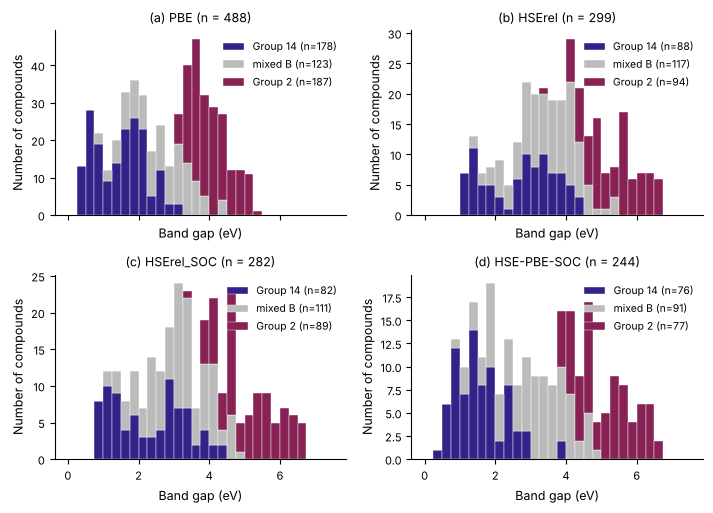

saved table fig01_gap_summary.csv shape (16, 7)


,level,group,n,mean_eV,std_eV,min_eV,max_eV
0,PBE,Group 14,178,1.491,0.719,0.370,3.145
1,PBE,mixed B,123,2.637,0.833,0.795,4.368
2,PBE,Group 2,187,4.010,0.547,3.084,5.367
3,PBE,all,488,2.745,1.291,0.370,5.367
4,HSErel,Group 14,88,2.714,0.987,1.090,4.440
5,HSErel,mixed B,117,3.459,0.861,1.391,5.322
6,HSErel,Group 2,94,5.286,0.762,3.465,6.694
7,HSErel,all,299,3.814,1.358,1.090,6.694
8,HSErel_SOC,Group 14,82,2.309,1.029,0.758,4.421
9,HSErel_SOC,mixed B,111,3.099,0.890,1.070,4.866


In [17]:
# fig01: gap histograms per level, stacked by strict group
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2), sharex=True)
bins = np.arange(0, 7.75, 0.25)
for ax, level, letter in zip(axes.ravel(), LEVELS, "abcd"):
    stacks = []
    for group_name in GROUP_ORDER:
        values = features.loc[features["strict_group"] == group_name, GAP_COL[level]].dropna()
        stacks.append(values)
    ax.hist(stacks, bins=bins, stacked=True, color=[COLOR_GROUP[g] for g in GROUP_ORDER],
            label=[g + " (n=%d)" % len(s) for g, s in zip(GROUP_ORDER, stacks)], edgecolor="white", linewidth=0.3)
    ax.set_title("%s (n = %d)" % (level, features[GAP_COL[level]].notna().sum()))
    ax.set_xlabel("Band gap (eV)")
    ax.set_ylabel("Number of compounds")
    ax.legend(frameon=False)
    panel_label(ax, letter)
fig.tight_layout()
save_fig(fig, "fig01_gap_hist")

gap_summary_rows = []
for level in LEVELS:
    for group_name in GROUP_ORDER + ["all"]:
        if group_name == "all":
            values = features[GAP_COL[level]].dropna()
        else:
            values = features.loc[features["strict_group"] == group_name, GAP_COL[level]].dropna()
        gap_summary_rows.append({"level": level, "group": group_name, "n": len(values), "mean_eV": values.mean(),
                                 "std_eV": values.std(), "min_eV": values.min(), "max_eV": values.max()})
gap_summary = pd.DataFrame(gap_summary_rows).round(3)
save_table(gap_summary, "fig01_gap_summary")
gap_summary

### Outlier identification (flagged, never dropped)
For each B category (single B element, or mixed B site) we take the median of a level-to-level difference and flag
compounds that lie more than 3 robust standard deviations (1.4826 x median absolute deviation) away from it.

In [18]:
def robust_outliers(table, value_column, category_column, threshold=3.0):
    """Flag rows whose value is far from the median of their category (robust z-score)."""
    flags = pd.Series(False, index=table.index)
    z_scores = pd.Series(np.nan, index=table.index)
    for category, part in table.groupby(category_column):
        values = part[value_column].dropna()
        if len(values) < 5:
            continue
        median = values.median()
        mad = 1.4826 * (values - median).abs().median()
        if mad == 0:
            continue
        z = (values - median) / mad
        z_scores.loc[z.index] = z
        flags.loc[z.index] = z.abs() > threshold
    return flags, z_scores


outlier_rows = []
for diff_column, description in [("hybrid_shift", "HSE-PBE-SOC minus PBE"),
                                 ("hserel_minus_pbe", "HSErel minus PBE"),
                                 ("hsesoc_minus_pbe", "HSErel_SOC minus PBE")]:
    flags, z_scores = robust_outliers(features, diff_column, "B_category")
    features["outlier_" + diff_column] = flags
    for index in features.index[flags]:
        outlier_rows.append({"difference": description, "Formula": features.loc[index, "Formula"],
                             "B_category": features.loc[index, "B_category"],
                             "gap_PBE": features.loc[index, G_PBE], "gap_HSErel": features.loc[index, G_HSE],
                             "gap_HSErel_SOC": features.loc[index, G_HSESOC], "gap_HSE_PBE_SOC": features.loc[index, G_HPS],
                             "difference_eV": features.loc[index, diff_column], "robust_z": z_scores.loc[index]})
outlier_table = pd.DataFrame(outlier_rows).round(3)
save_table(outlier_table, "stage1_outliers")
print("Flagged rows per difference:")
print(outlier_table["difference"].value_counts())
# Compounds with no PBE gap cannot enter these differences; list them separately
print("\nNot testable (no PBE gap):", features.loc[features[G_PBE].isna(), "Formula"].tolist())
outlier_table.sort_values(["difference", "robust_z"]).to_string()
record("n_outliers_hybrid_shift", int(features["outlier_hybrid_shift"].sum()), "stage 1")
record("n_outliers_hserel_minus_pbe", int(features["outlier_hserel_minus_pbe"].sum()), "stage 1")
record("n_outliers_hsesoc_minus_pbe", int(features["outlier_hsesoc_minus_pbe"].sum()), "stage 1")
outlier_table

saved table stage1_outliers.csv shape (16, 9)
Flagged rows per difference:
difference
HSErel minus PBE         10
HSErel_SOC minus PBE      4
HSE-PBE-SOC minus PBE     2
Name: count, dtype: int64

Not testable (no PBE gap): ['RbGeBr_1.125Cl_1.875', 'Rb_0.375Cs_0.625GeBr_3']


,difference,Formula,B_category,gap_PBE,gap_HSErel,gap_HSErel_SOC,gap_HSE_PBE_SOC,difference_eV,robust_z
0,HSE-PBE-SOC minus PBE,FACa_0.5Sr_0.5Cl_3,mixed B site,4.465,6.124,6.120,6.040,1.575,3.796
1,HSE-PBE-SOC minus PBE,FASr_0.5Ba_0.5Cl_3,mixed B site,4.312,6.236,6.233,5.895,1.583,3.821
2,HSErel minus PBE,FABa_0.125Ge_0.125Sn_0.75I_3,mixed B site,1.257,2.772,2.633,NaN,1.516,3.490
3,HSErel minus PBE,FACa_0.5Sr_0.5Cl_3,mixed B site,4.465,6.124,6.120,6.040,1.659,4.210
4,HSErel minus PBE,FAGe_0.5Pb_0.5Br_3,mixed B site,2.021,3.761,3.426,NaN,1.740,4.613
5,HSErel minus PBE,FASr_0.125Ba_0.125Ge_0.125Sn_0.25Pb_0.375Cl_3,mixed B site,2.459,4.203,3.744,2.860,1.744,4.636
6,HSErel minus PBE,FASr_0.5Ba_0.5Cl_3,mixed B site,4.312,6.236,6.233,5.895,1.924,5.537
7,HSErel minus PBE,MABa_0.125Sn_0.875I_3,mixed B site,1.111,2.582,2.407,1.411,1.472,3.269
8,HSErel minus PBE,MACa_0.125Sn_0.5Pb_0.375Cl_3,mixed B site,2.008,3.581,3.060,2.231,1.573,3.777
9,HSErel minus PBE,MACa_0.125Sn_0.75Pb_0.125I_3,mixed B site,1.038,2.676,2.379,1.226,1.638,4.106


In [19]:
# Where do the points near PBE gap of 3 to 3.5 eV and near 4.3 eV come from? (counts by strict group)
window_rows = []
for low, high in [(3.0, 3.5), (4.2, 4.4)]:
    in_window = features[(features[G_PBE] >= low) & (features[G_PBE] <= high)]
    for group_name in GROUP_ORDER:
        part = in_window[in_window["strict_group"] == group_name]
        window_rows.append({"PBE_window_eV": "%.1f-%.1f" % (low, high), "group": group_name, "n": len(part),
                            "n_flagged_any": int((part["outlier_hybrid_shift"] | part["outlier_hserel_minus_pbe"]
                                                  | part["outlier_hsesoc_minus_pbe"]).sum())})
window_table = pd.DataFrame(window_rows)
save_table(window_table, "stage1_pbe_windows")
window_table

saved table stage1_pbe_windows.csv shape (6, 4)


,PBE_window_eV,group,n,n_flagged_any
0,3.0-3.5,Group 14,3,0
1,3.0-3.5,mixed B,30,0
2,3.0-3.5,Group 2,34,0
3,4.2-4.4,Group 14,0,0
4,4.2-4.4,mixed B,4,0
5,4.2-4.4,Group 2,22,1


saved fig02_pbe_vs_hybrid_panel.png


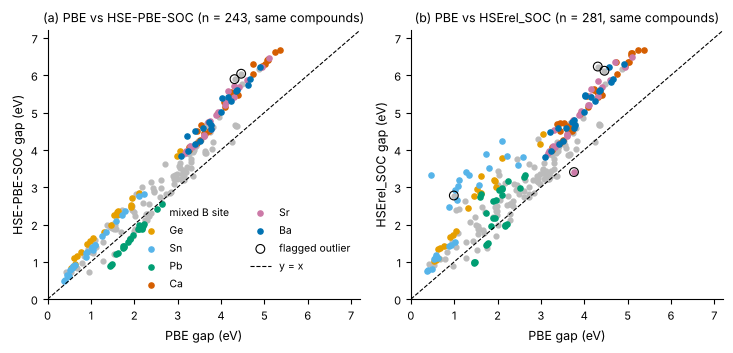

saved table fig02_level_minus_pbe_by_B.csv shape (21, 6)


,level,B_category,n,mean_level_minus_PBE_eV,std_eV,n_below_PBE
0,HSE-PBE-SOC,Ge,21,0.590,0.173,0
1,HSE-PBE-SOC,Sn,24,0.347,0.148,0
2,HSE-PBE-SOC,Pb,22,-0.306,0.129,22
3,HSE-PBE-SOC,Ca,25,1.114,0.242,0
4,HSE-PBE-SOC,Sr,22,1.025,0.239,0
5,HSE-PBE-SOC,Ba,19,1.043,0.213,0
6,HSE-PBE-SOC,mixed B site,110,0.405,0.377,15
7,HSErel_SOC,Ge,21,1.028,0.378,0
8,HSErel_SOC,Sn,26,1.268,0.758,0
9,HSErel_SOC,Pb,25,0.325,0.554,9


In [20]:
# fig02: PBE versus hybrid gaps, coloured by B element (single-B compounds); mixed-B compounds in grey
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.6))
for ax, level, letter in zip(axes, ["HSE-PBE-SOC", "HSErel_SOC"], "ab"):
    pair = features.dropna(subset=[G_PBE, GAP_COL[level]])
    mixed = pair[~pair["single_B"]]
    ax.scatter(mixed[G_PBE], mixed[GAP_COL[level]], s=12, color=COLOR_GROUP["mixed B"], label="mixed B site", zorder=1)
    for element in B_ELEMENTS:
        part = pair[pair["B_category"] == element]
        ax.scatter(part[G_PBE], part[GAP_COL[level]], s=14, color=COLOR_B[element], label=element, zorder=2)
    flag_column = "outlier_hybrid_shift" if level == "HSE-PBE-SOC" else "outlier_hsesoc_minus_pbe"
    flagged = pair[pair[flag_column]]
    ax.scatter(flagged[G_PBE], flagged[GAP_COL[level]], s=40, facecolors="none", edgecolors="black",
               linewidths=0.8, label="flagged outlier", zorder=3)
    ax.plot([0, 7.2], [0, 7.2], color="black", linewidth=0.8, linestyle="--", label="y = x")
    ax.set_xlim(0, 7.2)
    ax.set_ylim(0, 7.2)
    ax.set_xlabel("PBE gap (eV)")
    ax.set_ylabel(level + " gap (eV)")
    ax.set_title("PBE vs %s (n = %d, same compounds)" % (level, len(pair)))
    panel_label(ax, letter)
axes[0].legend(frameon=False, ncol=2, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig02_pbe_vs_hybrid_panel")

# Error cancellation for Pb: how often is the HSE+SOC gap BELOW the PBE gap?
cancel_rows = []
for level in ["HSE-PBE-SOC", "HSErel_SOC", "HSErel"]:
    pair = features.dropna(subset=[G_PBE, GAP_COL[level]])
    for category in B_ELEMENTS + ["mixed B site"]:
        part = pair[pair["B_category"] == category]
        difference = part[GAP_COL[level]] - part[G_PBE]
        cancel_rows.append({"level": level, "B_category": category, "n": len(part),
                            "mean_level_minus_PBE_eV": difference.mean(), "std_eV": difference.std(),
                            "n_below_PBE": int((difference < 0).sum())})
cancel_table = pd.DataFrame(cancel_rows).round(3)
save_table(cancel_table, "fig02_level_minus_pbe_by_B")
for row in cancel_table.itertuples():
    record("mean_%s_minus_PBE_%s" % (row.level, row.B_category.replace(" ", "_")), row.mean_level_minus_PBE_eV, "stage 1",
           "single-B compounds, n=%d" % row.n)
cancel_table

saved fig03_shifts_by_B.png


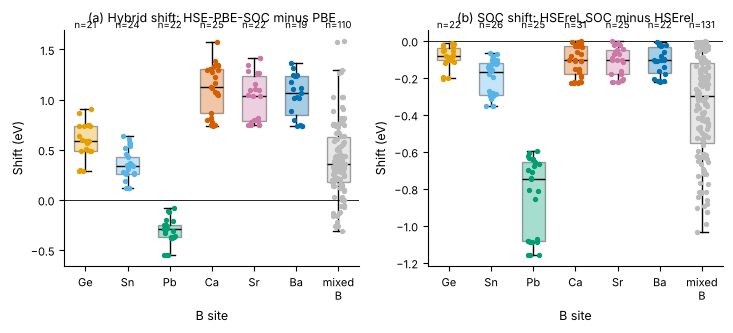

saved table fig03_shifts_by_B.csv shape (14, 7)


,shift,B_category,n,mean_eV,std_eV,min_eV,max_eV
0,hybrid_shift,Ge,21,0.590,0.173,0.292,0.909
1,hybrid_shift,Sn,24,0.347,0.148,0.116,0.643
2,hybrid_shift,Pb,22,-0.306,0.129,-0.548,-0.078
3,hybrid_shift,Ca,25,1.114,0.242,0.739,1.572
4,hybrid_shift,Sr,22,1.025,0.239,0.743,1.417
5,hybrid_shift,Ba,19,1.043,0.213,0.735,1.367
6,hybrid_shift,mixed B site,110,0.405,0.377,-0.305,1.583
7,soc_shift,Ge,22,-0.084,0.058,-0.206,-0.009
8,soc_shift,Sn,26,-0.201,0.098,-0.352,-0.063
9,soc_shift,Pb,25,-0.843,0.213,-1.157,-0.595


In [21]:
# fig03: hybrid shift and SOC shift by B element (single-B compounds) plus the mixed-B compounds
categories = B_ELEMENTS + ["mixed B site"]
category_colours = [COLOR_B[e] for e in B_ELEMENTS] + [COLOR_GROUP["mixed B"]]
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4))
shift_rows = []
for ax, shift_column, title, letter in zip(axes, ["hybrid_shift", "soc_shift"],
                                           ["Hybrid shift: HSE-PBE-SOC minus PBE", "SOC shift: HSErel_SOC minus HSErel"], "ab"):
    data_per_category = []
    for category in categories:
        values = features.loc[features["B_category"] == category, shift_column].dropna()
        data_per_category.append(values.values)
        shift_rows.append({"shift": shift_column, "B_category": category, "n": len(values), "mean_eV": values.mean(),
                           "std_eV": values.std(), "min_eV": values.min(), "max_eV": values.max()})
    box = ax.boxplot(data_per_category, widths=0.55, patch_artist=True, showfliers=False)
    for patch, colour in zip(box["boxes"], category_colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.35)
    for median_line in box["medians"]:
        median_line.set_color("black")
    rng = np.random.default_rng(RANDOM_STATE)
    for position, (values, colour) in enumerate(zip(data_per_category, category_colours), start=1):
        jitter = rng.uniform(-0.15, 0.15, size=len(values))
        ax.scatter(position + jitter, values, s=8, color=colour, zorder=3)
        ax.text(position, 1.01, "n=%d" % len(values), transform=ax.get_xaxis_transform(), ha="center", fontsize=7)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xticks(range(1, len(categories) + 1))
    ax.set_xticklabels(["Ge", "Sn", "Pb", "Ca", "Sr", "Ba", "mixed\nB"])
    ax.set_ylabel("Shift (eV)")
    ax.set_xlabel("B site")
    ax.set_title(title, pad=14)
    panel_label(ax, letter)
fig.tight_layout()
save_fig(fig, "fig03_shifts_by_B")
shift_table = pd.DataFrame(shift_rows).round(3)
save_table(shift_table, "fig03_shifts_by_B")
for row in shift_table.itertuples():
    record("%s_mean_%s" % (row.shift, row.B_category.replace(" ", "_")), row.mean_eV, "stage 1", "single-B, n=%d" % row.n)
shift_table

In [22]:
# SOC shift on PURE compounds (one element per site): means per B element (compare with CLAUDE.md section 9 item 1)
pure = features[features["pure"]].copy()
pure["A_label"] = pure["A_main"].map(A_LABEL)
soc_pure_rows = []
for element in B_ELEMENTS:
    values = pure.loc[pure["B_main"] == element, "soc_shift"].dropna()
    values_no_equal = pure.loc[(pure["B_main"] == element) & (~pure["equal_flag"]), "soc_shift"].dropna()
    n_equal = int((pure["B_main"] == element).mul(pure["equal_flag"]).sum())
    soc_pure_rows.append({"B": element, "Z_B": Z_NUMBER[element], "n": len(values), "mean_soc_shift_eV": values.mean(),
                          "std_eV": values.std(), "n_equal_flag_rows": n_equal,
                          "n_without_equal_flag": len(values_no_equal),
                          "mean_without_equal_flag_eV": values_no_equal.mean()})
soc_pure_table = pd.DataFrame(soc_pure_rows).round(3)
save_table(soc_pure_table, "fig04_soc_shift_pure_by_B")
for row in soc_pure_table.itertuples():
    record("soc_shift_pure_mean_" + row.B, row.mean_soc_shift_eV, "stage 1", "pure compounds, n=%d" % row.n)
    record("soc_shift_pure_mean_noequal_" + row.B, row.mean_without_equal_flag_eV, "stage 1",
           "pure compounds without equal_flag rows, n=%d" % row.n_without_equal_flag)
soc_pure_table

saved table fig04_soc_shift_pure_by_B.csv shape (6, 8)


,B,Z_B,n,mean_soc_shift_eV,std_eV,n_equal_flag_rows,n_without_equal_flag,mean_without_equal_flag_eV
0,Ge,32,15,-0.098,0.064,0,15,-0.098
1,Sn,50,15,-0.235,0.101,0,15,-0.235
2,Pb,82,15,-0.961,0.194,0,15,-0.961
3,Ca,20,15,-0.107,0.087,9,6,-0.088
4,Sr,38,14,-0.095,0.083,7,7,-0.060
5,Ba,56,15,-0.106,0.080,6,9,-0.134


saved fig04_soc_vs_ZB.png


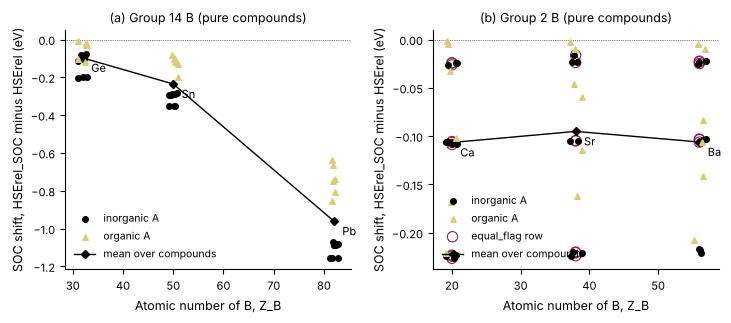

In [23]:
# fig04: SOC shift versus Z_B, pure compounds. (a) Group 14 with mean line, (b) Group 2.
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3), sharey=False)
rng = np.random.default_rng(RANDOM_STATE)
for ax, elements, title, letter in zip(axes, [GROUP14_B, GROUP2_B], ["Group 14 B (pure compounds)", "Group 2 B (pure compounds)"], "ab"):
    means = []
    for element in elements:
        part = pure[(pure["B_main"] == element)].dropna(subset=["soc_shift"])
        for a_type in ["inorganic A", "organic A"]:
            sub = part[part["A_type"] == a_type]
            jitter = rng.uniform(-1.0, 1.0, size=len(sub))
            ax.scatter(Z_NUMBER[element] + jitter, sub["soc_shift"], s=16, color=COLOR_ATYPE[a_type],
                       marker=MARKER_ATYPE[a_type], label=a_type if element == elements[0] else None, zorder=3)
        flagged = part[part["equal_flag"]]
        ax.scatter([Z_NUMBER[element]] * len(flagged), flagged["soc_shift"], s=55, facecolors="none",
                   edgecolors=COLOR_GROUP["Group 2"], linewidths=0.8,
                   label="equal_flag row" if (element == elements[0] and len(flagged) > 0) else None, zorder=2)
        means.append(part["soc_shift"].mean())
    ax.plot([Z_NUMBER[e] for e in elements], means, color="black", linewidth=1.0, marker="D", markersize=4,
            label="mean over compounds")
    for element, mean_value in zip(elements, means):
        ax.annotate(element, (Z_NUMBER[element], mean_value), textcoords="offset points", xytext=(6, -10), fontsize=8)
    ax.axhline(0, color="black", linewidth=0.5, linestyle=":")
    ax.set_xlabel("Atomic number of B, Z_B")
    ax.set_ylabel("SOC shift, HSErel_SOC minus HSErel (eV)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="lower left")
    panel_label(ax, letter)
fig.tight_layout()
save_fig(fig, "fig04_soc_vs_ZB")

saved table fig05_soc_grid_B_by_X.csv shape (18, 5)


saved table fig05_soc_shift_per_A.csv shape (18, 7)


saved fig05_soc_grid_panel.png


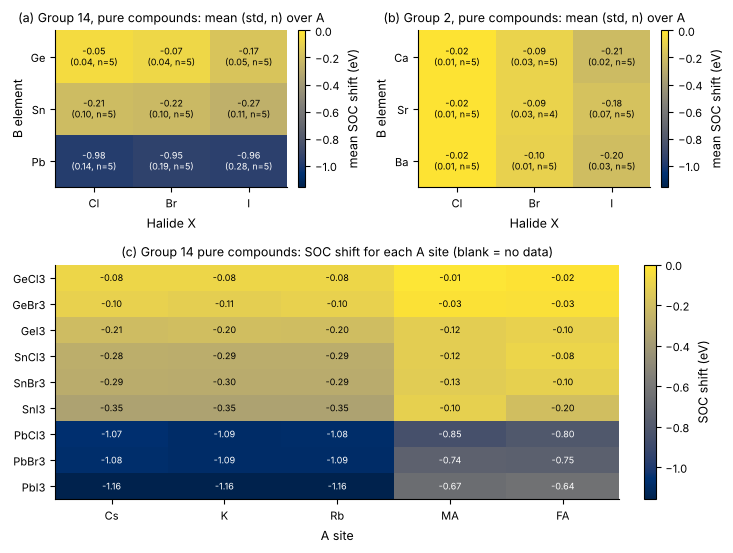

saved table fig05_soc_shift_inorganic_vs_organic.csv shape (9, 6)
compound  mean_inorganic_A_eV  n_inorganic  mean_organic_A_eV  n_organic  organic_minus_inorganic_eV
   GeCl3               -0.080            3             -0.014          2                       0.066
   GeBr3               -0.105            3             -0.028          2                       0.076
    GeI3               -0.201            3             -0.111          2                       0.090
   SnCl3               -0.285            3             -0.102          2                       0.184
   SnBr3               -0.295            3             -0.115          2                       0.179
    SnI3               -0.351            3             -0.150          2                       0.200
   PbCl3               -1.080            3             -0.828          2                       0.252
   PbBr3               -1.084            3             -0.744          2                       0.340
    PbI3               -1

,B,X,Cs,K,Rb,MA,FA
0,Ge,Cl,-0.081,-0.079,-0.080,-0.009,-0.019
1,Ge,Br,-0.101,-0.113,-0.100,-0.027,-0.030
2,Ge,I,-0.206,-0.197,-0.201,-0.120,-0.102
3,Sn,Cl,-0.283,-0.287,-0.286,-0.119,-0.084
4,Sn,Br,-0.293,-0.296,-0.295,-0.127,-0.104
5,Sn,I,-0.352,-0.350,-0.351,-0.104,-0.197
6,Pb,Cl,-1.070,-1.088,-1.083,-0.853,-0.804
7,Pb,Br,-1.079,-1.088,-1.086,-0.740,-0.749
8,Pb,I,-1.157,-1.157,-1.157,-0.666,-0.639
9,Ca,Cl,-0.026,-0.024,-0.024,-0.005,-0.002


In [24]:
# fig05: SOC shift grids. (a) Group 14 B x halide, (b) Group 2 B x halide, (c) per A site for Group 14.
def grid_table(table, row_elements, value_column):
    mean_grid = pd.DataFrame(index=row_elements, columns=X_ELEMENTS, dtype=float)
    std_grid = mean_grid.copy()
    n_grid = mean_grid.copy()
    for b_element in row_elements:
        for x_element in X_ELEMENTS:
            values = table.loc[(table["B_main"] == b_element) & (table["X_main"] == x_element), value_column].dropna()
            mean_grid.loc[b_element, x_element] = values.mean()
            std_grid.loc[b_element, x_element] = values.std()
            n_grid.loc[b_element, x_element] = len(values)
    return mean_grid, std_grid, n_grid


def draw_heatmap(ax, values, text, row_labels, col_labels, vmin, vmax, colorbar_label):
    image = ax.imshow(values, cmap="cividis", vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            shade = (values[i, j] - vmin) / (vmax - vmin) if np.isfinite(values[i, j]) else 1
            ax.text(j, i, text[i][j], ha="center", va="center", fontsize=6.5,
                    color="white" if shade < 0.5 else "black")
    ax.set_xticks(range(len(col_labels)))
    ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels)
    colorbar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label(colorbar_label)


soc_grid_rows = []
grids = {}
for name, elements in [("Group 14", GROUP14_B), ("Group 2", GROUP2_B)]:
    mean_grid, std_grid, n_grid = grid_table(pure, elements, "soc_shift")
    grids[name] = (mean_grid, std_grid, n_grid)
    for b_element in elements:
        for x_element in X_ELEMENTS:
            soc_grid_rows.append({"B": b_element, "X": x_element, "mean_soc_shift_eV": mean_grid.loc[b_element, x_element],
                                  "std_eV": std_grid.loc[b_element, x_element], "n": int(n_grid.loc[b_element, x_element])})
soc_grid_table = pd.DataFrame(soc_grid_rows).round(3)
save_table(soc_grid_table, "fig05_soc_grid_B_by_X")

# per A site table (pure compounds, Group 14 and Group 2)
per_a_rows = []
for b_element in B_ELEMENTS:
    for x_element in X_ELEMENTS:
        row = {"B": b_element, "X": x_element}
        for a_element in A_ELEMENTS:
            values = pure.loc[(pure["B_main"] == b_element) & (pure["X_main"] == x_element) &
                              (pure["A_main"] == a_element), "soc_shift"].dropna()
            row[A_LABEL[a_element]] = values.mean() if len(values) == 1 else np.nan
        per_a_rows.append(row)
soc_per_a = pd.DataFrame(per_a_rows).round(3)
save_table(soc_per_a, "fig05_soc_shift_per_A")

fig = plt.figure(figsize=(7.4, 5.6))
grid_spec = fig.add_gridspec(2, 2, height_ratios=[1, 1.5])
ax_a = fig.add_subplot(grid_spec[0, 0])
ax_b = fig.add_subplot(grid_spec[0, 1])
ax_c = fig.add_subplot(grid_spec[1, :])
vmin = float(np.nanmin(soc_per_a[[A_LABEL[a] for a in A_ELEMENTS]].values))
vmax = 0.0
for ax, name, letter in [(ax_a, "Group 14", "a"), (ax_b, "Group 2", "b")]:
    mean_grid, std_grid, n_grid = grids[name]
    text = [["%.2f\n(%.2f, n=%d)" % (mean_grid.iloc[i, j], std_grid.iloc[i, j], n_grid.iloc[i, j])
             for j in range(3)] for i in range(3)]
    draw_heatmap(ax, mean_grid.values.astype(float), text, list(mean_grid.index), X_ELEMENTS, vmin, vmax, "mean SOC shift (eV)")
    ax.set_title("%s, pure compounds: mean (std, n) over A" % name)
    ax.set_xlabel("Halide X")
    ax.set_ylabel("B element")
    panel_label(ax, letter)
g14_per_a = soc_per_a[soc_per_a["B"].isin(GROUP14_B)]
values_c = g14_per_a[[A_LABEL[a] for a in A_ELEMENTS]].values.astype(float)
text_c = [["" if not np.isfinite(v) else "%.2f" % v for v in row] for row in values_c]
draw_heatmap(ax_c, values_c, text_c, (g14_per_a["B"] + g14_per_a["X"] + "3").tolist(),
             [A_LABEL[a] for a in A_ELEMENTS], vmin, vmax, "SOC shift (eV)")
ax_c.set_title("Group 14 pure compounds: SOC shift for each A site (blank = no data)")
ax_c.set_xlabel("A site")
panel_label(ax_c, "c")
fig.tight_layout()
save_fig(fig, "fig05_soc_grid_panel")

# A-site dependence summary: inorganic (Cs, K, Rb) versus organic (MA, FA) for each Group 14 B x X
a_dependence_rows = []
for row in g14_per_a.itertuples():
    inorganic_values = [getattr(row, a) for a in ["Cs", "K", "Rb"] if np.isfinite(getattr(row, a))]
    organic_values = [getattr(row, a) for a in ["MA", "FA"] if np.isfinite(getattr(row, a))]
    a_dependence_rows.append({"compound": row.B + row.X + "3", "mean_inorganic_A_eV": np.mean(inorganic_values) if inorganic_values else np.nan,
                              "n_inorganic": len(inorganic_values),
                              "mean_organic_A_eV": np.mean(organic_values) if organic_values else np.nan,
                              "n_organic": len(organic_values)})
a_dependence = pd.DataFrame(a_dependence_rows)
a_dependence["organic_minus_inorganic_eV"] = a_dependence["mean_organic_A_eV"] - a_dependence["mean_inorganic_A_eV"]
a_dependence = a_dependence.round(3)
save_table(a_dependence, "fig05_soc_shift_inorganic_vs_organic")
for row in soc_per_a.itertuples():
    for a_label in ["Cs", "K", "Rb", "MA", "FA"]:
        value = getattr(row, a_label)
        if np.isfinite(value):
            record("soc_shift_%s%s%s3" % (a_label, row.B, row.X), value, "stage 1", "pure compound")
print(a_dependence.to_string(index=False))
soc_per_a

### Gap versus geometry and correlation overview
Question: how do the gap and the geometric/electronic descriptors relate, before any model is fitted?
Pearson correlations are computed on the compounds that have the gap at the level shown.

saved fig07_gap_vs_geometry.png


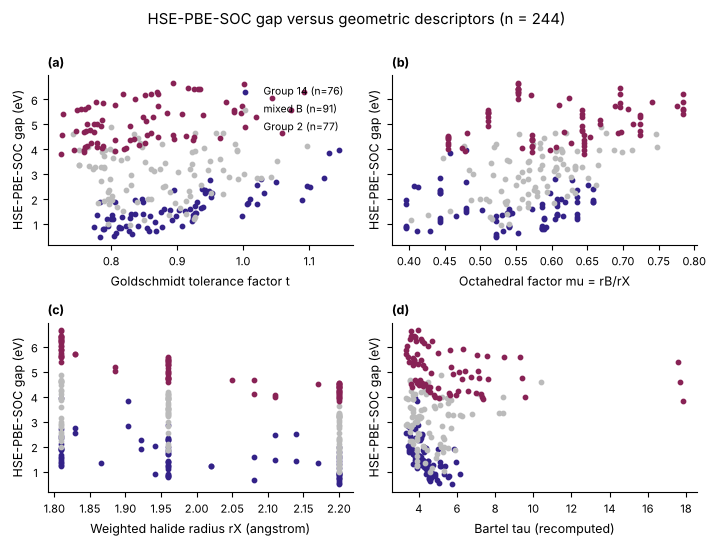

saved table fig07_gap_vs_geometry_correlations.csv shape (16, 5)


,descriptor,group,n,pearson_r,spearman_rho
0,tolerance,Group 14,76,0.781,0.736
1,tolerance,mixed B,91,0.056,0.014
2,tolerance,Group 2,77,0.431,0.426
3,tolerance,all,244,0.007,-0.035
4,octahedral,Group 14,76,0.002,0.145
5,octahedral,mixed B,91,0.504,0.478
6,octahedral,Group 2,77,0.246,0.207
7,octahedral,all,244,0.408,0.375
8,rX,Group 14,76,-0.473,-0.504
9,rX,mixed B,91,-0.566,-0.547


In [25]:
# fig07: HSE-PBE-SOC gap versus geometric descriptors, coloured by strict group
geometry_plot_columns = [("tolerance", "Goldschmidt tolerance factor t"), ("octahedral", "Octahedral factor mu = rB/rX"),
                         ("rX", "Weighted halide radius rX (angstrom)"), ("bartel_tau", "Bartel tau (recomputed)")]
hps = features.dropna(subset=[G_HPS])
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharey=True)
for ax, (column, label), letter in zip(axes.ravel(), geometry_plot_columns, "abcd"):
    for group_name in GROUP_ORDER:
        part = hps[hps["strict_group"] == group_name]
        ax.scatter(part[column], part[G_HPS], s=10, color=COLOR_GROUP[group_name], label=group_name + " (n=%d)" % len(part))
    ax.set_xlabel(label)
    ax.set_ylabel("HSE-PBE-SOC gap (eV)")
    panel_label(ax, letter)
axes[0, 0].legend(frameon=False)
fig.suptitle("HSE-PBE-SOC gap versus geometric descriptors (n = %d)" % len(hps), y=1.0)
fig.tight_layout()
save_fig(fig, "fig07_gap_vs_geometry")

geometry_corr_rows = []
for column, label in geometry_plot_columns:
    for group_name in GROUP_ORDER + ["all"]:
        part = hps if group_name == "all" else hps[hps["strict_group"] == group_name]
        geometry_corr_rows.append({"descriptor": column, "group": group_name, "n": len(part),
                                   "pearson_r": part[column].corr(part[G_HPS]),
                                   "spearman_rho": part[column].corr(part[G_HPS], method="spearman")})
geometry_corr = pd.DataFrame(geometry_corr_rows).round(3)
save_table(geometry_corr, "fig07_gap_vs_geometry_correlations")
geometry_corr

saved fig08_corr_heatmap.png


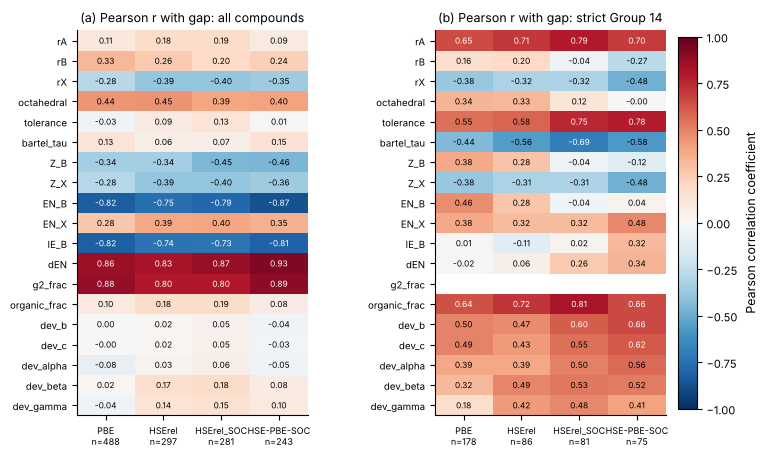

saved table fig08_corr_with_gap_all_compounds.csv shape (19, 5)
saved table fig08_corr_with_gap_strict_Group_14.csv shape (19, 5)
saved table fig08_feature_feature_corr.csv shape (19, 20)
numbers.json now holds 154 numbers


In [26]:
# fig08: correlation of each descriptor with the gap at each level; (a) all compounds, (b) strict Group 14
corr_descriptors = GEOM_FEATURES + ["bartel_tau"] + Z_FEATURES + ELEC_FEATURES + ["g2_frac", "organic_frac"] + DEV_COLS
fig, axes = plt.subplots(1, 2, figsize=(8.0, 5.0))
corr_tables = {}
for ax, (subset_name, subset), letter in zip(axes, [("all compounds", features),
                                                   ("strict Group 14", features[features["strict_group"] == "Group 14"])], "ab"):
    matrix = pd.DataFrame(index=corr_descriptors, columns=LEVELS, dtype=float)
    counts = {}
    for level in LEVELS:
        part = subset.dropna(subset=[GAP_COL[level]] + DEV_COLS)
        counts[level] = len(part)
        for descriptor in corr_descriptors:
            if part[descriptor].std() > 0:
                matrix.loc[descriptor, level] = part[descriptor].corr(part[GAP_COL[level]])
    corr_tables[subset_name] = matrix
    image = ax.imshow(matrix.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]
            ax.text(j, i, "" if not np.isfinite(value) else "%.2f" % value, ha="center", va="center", fontsize=6,
                    color="white" if np.isfinite(value) and abs(value) > 0.6 else "black")
    ax.set_xticks(range(len(LEVELS)))
    ax.set_xticklabels([lvl + "\nn=%d" % counts[lvl] for lvl in LEVELS], fontsize=6.5)
    ax.set_yticks(range(len(corr_descriptors)))
    ax.set_yticklabels(corr_descriptors, fontsize=7)
    ax.set_title("Pearson r with gap: " + subset_name)
    panel_label(ax, letter)
fig.subplots_adjust(wspace=0.55)
colorbar = fig.colorbar(image, ax=axes, fraction=0.03, pad=0.02)
colorbar.set_label("Pearson correlation coefficient")
save_fig(fig, "fig08_corr_heatmap")
for subset_name, matrix in corr_tables.items():
    save_table(matrix.round(3).reset_index().rename(columns={"index": "descriptor"}),
               "fig08_corr_with_gap_" + subset_name.replace(" ", "_"))
# Feature-feature correlation matrix (all compounds with a PBE entry), saved as a table only
feature_feature = features.dropna(subset=DEV_COLS)[corr_descriptors].corr().round(3)
save_table(feature_feature.reset_index().rename(columns={"index": "descriptor"}), "fig08_feature_feature_corr")
write_numbers()

## Stage 2: halide trends and halide mixing

Question: how does the gap change from Cl to Br to I for each B element, at PBE and at HSE-PBE-SOC on the same
compounds? For mixed halides, how far does the gap deviate from a straight line between the two pure end members (bowing)?

In [27]:
# Earlier exploratory values from CLAUDE.md section 9, item 2 (for comparison only; they are NOT used in any calculation)
EARLIER_HALIDE_TREND = {
    "PBE": {"Pb": [2.34, 1.87, 1.64], "Sn": [1.37, 0.87, 0.64], "Ge": [1.59, 1.16, 0.91],
            "Ca": [5.01, 4.20, 3.49], "Sr": [4.76, 4.04, 3.43], "Ba": [4.53, 3.91, 3.36]},
    "HSE-PBE-SOC": {"Pb": [2.04, 1.55, 1.07], "Sn": [1.50, 1.21, 0.81], "Ge": [2.27, 1.73, 1.28],
                    "Ca": [6.37, 5.32, 4.29], "Sr": [6.06, 5.16, 4.23], "Ba": [5.78, 5.01, 4.20]},
}

# Mean gap of pure compounds for each B x X: (i) on all compounds available at that level, (ii) on the SAME compounds
same_set = pure.dropna(subset=[G_PBE, G_HPS])
trend_rows = []
for b_element in B_ELEMENTS:
    for x_index, x_element in enumerate(X_ELEMENTS):
        cell_all = pure[(pure["B_main"] == b_element) & (pure["X_main"] == x_element)]
        cell_same = same_set[(same_set["B_main"] == b_element) & (same_set["X_main"] == x_element)]
        row = {"B": b_element, "X": x_element}
        for level in LEVELS:
            values = cell_all[GAP_COL[level]].dropna()
            row["n_all_" + level] = len(values)
            row["mean_all_" + level] = values.mean()
        row["n_same"] = len(cell_same)
        row["same_compounds"] = ",".join(cell_same["A_main"].map(A_LABEL))
        row["mean_same_PBE"] = cell_same[G_PBE].mean()
        row["std_same_PBE"] = cell_same[G_PBE].std()
        row["mean_same_HSE_PBE_SOC"] = cell_same[G_HPS].mean()
        row["std_same_HSE_PBE_SOC"] = cell_same[G_HPS].std()
        row["earlier_PBE"] = EARLIER_HALIDE_TREND["PBE"][b_element][x_index]
        row["earlier_HSE_PBE_SOC"] = EARLIER_HALIDE_TREND["HSE-PBE-SOC"][b_element][x_index]
        trend_rows.append(row)
halide_trend = pd.DataFrame(trend_rows)
halide_trend["diff_all_PBE_vs_earlier"] = halide_trend["mean_all_PBE"] - halide_trend["earlier_PBE"]
halide_trend["diff_all_HPS_vs_earlier"] = halide_trend["mean_all_HSE-PBE-SOC"] - halide_trend["earlier_HSE_PBE_SOC"]
halide_trend = halide_trend.round(3)
save_table(halide_trend, "fig06_halide_trend")
for row in halide_trend.itertuples():
    record("halide_trend_same_PBE_%s_%s" % (row.B, row.X), row.mean_same_PBE, "stage 2", "pure, same compounds, n=%d" % row.n_same)
    record("halide_trend_same_HPS_%s_%s" % (row.B, row.X), row.mean_same_HSE_PBE_SOC, "stage 2", "pure, same compounds, n=%d" % row.n_same)
    record("halide_trend_all_PBE_%s_%s" % (row.B, row.X), getattr(row, "mean_all_PBE"), "stage 2", "pure, all with PBE")
    record("halide_trend_all_HPS_%s_%s" % (row.B, row.X), halide_trend.loc[row.Index, "mean_all_HSE-PBE-SOC"],
           "stage 2", "pure, all with HSE-PBE-SOC, n=%d" % halide_trend.loc[row.Index, "n_all_HSE-PBE-SOC"])
halide_trend[["B", "X", "n_all_PBE", "mean_all_PBE", "earlier_PBE", "n_all_HSE-PBE-SOC", "mean_all_HSE-PBE-SOC",
              "earlier_HSE_PBE_SOC", "n_same", "same_compounds", "mean_same_PBE", "mean_same_HSE_PBE_SOC"]]

saved table fig06_halide_trend.csv shape (18, 20)


,B,X,n_all_PBE,mean_all_PBE,earlier_PBE,n_all_HSE-PBE-SOC,mean_all_HSE-PBE-SOC,earlier_HSE_PBE_SOC,n_same,same_compounds,mean_same_PBE,mean_same_HSE_PBE_SOC
0,Ge,Cl,5,1.585,1.59,5,2.272,2.27,5,"Cs,FA,K,MA,Rb",1.585,2.272
1,Ge,Br,5,1.156,1.16,5,1.729,1.73,5,"Cs,FA,K,MA,Rb",1.156,1.729
2,Ge,I,5,0.906,0.91,5,1.282,1.28,5,"Cs,FA,K,MA,Rb",0.906,1.282
3,Sn,Cl,5,1.374,1.37,4,1.498,1.50,4,"Cs,K,MA,Rb",1.102,1.498
4,Sn,Br,5,0.866,0.87,5,1.206,1.21,5,"Cs,FA,K,MA,Rb",0.866,1.206
5,Sn,I,5,0.639,0.64,5,0.815,0.81,5,"Cs,FA,K,MA,Rb",0.639,0.815
6,Pb,Cl,5,2.341,2.34,4,2.040,2.04,4,"Cs,K,MA,Rb",2.274,2.040
7,Pb,Br,5,1.871,1.87,5,1.553,1.55,5,"Cs,FA,K,MA,Rb",1.871,1.553
8,Pb,I,5,1.637,1.64,4,1.069,1.07,4,"Cs,K,MA,Rb",1.560,1.069
9,Ca,Cl,5,5.007,5.01,5,6.373,6.37,5,"Cs,FA,K,MA,Rb",5.007,6.373


In [28]:
# Does the gap fall from Cl to Br to I for every B (same-compound means)? And the Group 14 ordering at each halide.
monotonic_rows = []
for b_element in B_ELEMENTS:
    part = halide_trend[halide_trend["B"] == b_element].set_index("X")
    for column, level in [("mean_same_PBE", "PBE"), ("mean_same_HSE_PBE_SOC", "HSE-PBE-SOC")]:
        values = part.loc[X_ELEMENTS, column].values
        monotonic_rows.append({"B": b_element, "level": level, "Cl": values[0], "Br": values[1], "I": values[2],
                               "falls_Cl_to_I": bool(values[0] > values[1] > values[2])})
monotonic_table = pd.DataFrame(monotonic_rows)
save_table(monotonic_table.round(3), "stage2_halide_monotonic")
print(monotonic_table.round(3).to_string(index=False))
order_rows = []
for x_element in X_ELEMENTS:
    for column, level in [("mean_same_PBE", "PBE"), ("mean_same_HSE_PBE_SOC", "HSE-PBE-SOC")]:
        part = halide_trend[(halide_trend["X"] == x_element) & (halide_trend["B"].isin(GROUP14_B))]
        ordered = part.sort_values(column, ascending=False)["B"].tolist()
        order_rows.append({"X": x_element, "level": level, "Group 14 order (largest gap first)": " > ".join(ordered)})
order_table = pd.DataFrame(order_rows)
save_table(order_table, "stage2_group14_order")
order_table

saved table stage2_halide_monotonic.csv shape (12, 6)
 B       level    Cl    Br     I  falls_Cl_to_I
Ge         PBE 1.585 1.156 0.906           True
Ge HSE-PBE-SOC 2.272 1.729 1.282           True
Sn         PBE 1.102 0.866 0.639           True
Sn HSE-PBE-SOC 1.498 1.206 0.815           True
Pb         PBE 2.274 1.871 1.560           True
Pb HSE-PBE-SOC 2.040 1.553 1.069           True
Ca         PBE 5.007 4.198 3.502           True
Ca HSE-PBE-SOC 6.373 5.321 4.291           True
Sr         PBE 4.767 4.015 3.469           True
Sr HSE-PBE-SOC 6.057 5.163 4.231           True
Ba         PBE 4.519 3.911 3.361           True
Ba HSE-PBE-SOC 5.779 5.009 4.199           True
saved table stage2_group14_order.csv shape (6, 3)


,X,level,Group 14 order (largest gap first)
0,Cl,PBE,Pb > Ge > Sn
1,Cl,HSE-PBE-SOC,Ge > Pb > Sn
2,Br,PBE,Pb > Ge > Sn
3,Br,HSE-PBE-SOC,Ge > Pb > Sn
4,I,PBE,Pb > Ge > Sn
5,I,HSE-PBE-SOC,Ge > Pb > Sn


saved fig06_halide_trend.png


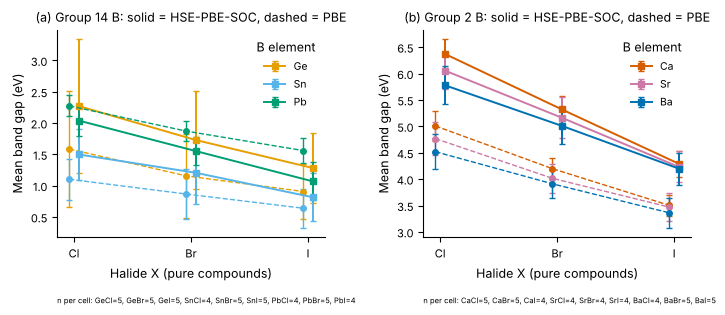

In [29]:
# fig06: mean gap of pure compounds versus halide, PBE (dashed) and HSE-PBE-SOC (solid), same compounds
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4), sharey=False)
x_positions = np.arange(3)
for ax, elements, title, letter in zip(axes, [GROUP14_B, GROUP2_B], ["Group 14 B", "Group 2 B"], "ab"):
    for b_element in elements:
        part = halide_trend[halide_trend["B"] == b_element].set_index("X").loc[X_ELEMENTS]
        ax.errorbar(x_positions - 0.04, part["mean_same_PBE"], yerr=part["std_same_PBE"], color=COLOR_B[b_element],
                    linestyle="--", marker="o", markersize=4, capsize=2, linewidth=1)
        ax.errorbar(x_positions + 0.04, part["mean_same_HSE_PBE_SOC"], yerr=part["std_same_HSE_PBE_SOC"],
                    color=COLOR_B[b_element], linestyle="-", marker="s", markersize=4, capsize=2, linewidth=1.4,
                    label=b_element)
    counts = halide_trend[halide_trend["B"].isin(elements)].set_index(["B", "X"])["n_same"]
    count_text = "n per cell: " + ", ".join("%s%s=%d" % (b, x, counts.loc[(b, x)]) for b in elements for x in X_ELEMENTS)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(X_ELEMENTS)
    ax.set_xlabel("Halide X (pure compounds)")
    ax.set_ylabel("Mean band gap (eV)")
    ax.set_title(title + ": solid = HSE-PBE-SOC, dashed = PBE")
    ax.text(0.0, -0.32, count_text, transform=ax.transAxes, fontsize=5.5, wrap=True)
    ax.legend(frameon=False, title="B element")
    panel_label(ax, letter)
fig.tight_layout()
save_fig(fig, "fig06_halide_trend")

### Mixed halides and bowing
For a compound A B (X1, X2)3 with the halide fraction x of the heavier halide (I in I-Br and I-Cl, Br in Br-Cl),
the linear interpolation is E_lin = x E(A B X1_3) + (1 - x) E(A B X2_3), using the pure end members with the same
A and B at the same level of theory. Deviation = E - E_lin. Bowing parameter b from E = E_lin - b x (1 - x).
Only compounds with a single A and a single B species are used (end members must exist at the same level).

In [30]:
HALIDE_PAIRS = [("I", "Br"), ("Br", "Cl"), ("I", "Cl")]
pure_lookup = pure.set_index(["A_main", "B_main", "X_main"])
x_mixed = features[(features["mixing_site"] == "X-mixed")].copy()
print("X-mixed compounds (single A, single B):", len(x_mixed))
bowing_rows = []
for index, row in x_mixed.iterrows():
    present = [x for x in X_ELEMENTS if row["frac_" + x] > 0]
    pair = [p for p in HALIDE_PAIRS if set(p) == set(present)][0]
    heavy, light = pair
    x_heavy = row["frac_" + heavy]
    for level in LEVELS:
        gap = row[GAP_COL[level]]
        key_heavy = (row["A_main"], row["B_main"], heavy)
        key_light = (row["A_main"], row["B_main"], light)
        if pd.isna(gap):
            continue
        end_heavy = pure_lookup.loc[key_heavy, GAP_COL[level]] if key_heavy in pure_lookup.index else np.nan
        end_light = pure_lookup.loc[key_light, GAP_COL[level]] if key_light in pure_lookup.index else np.nan
        linear = x_heavy * end_heavy + (1 - x_heavy) * end_light
        deviation = gap - linear
        bowing_rows.append({"Formula": row["Formula"], "level": level, "pair": heavy + "-" + light, "A": row["A_main"],
                            "B": row["B_main"], "group": row["strict_group"], "x_heavy": x_heavy, "gap_eV": gap,
                            "end_heavy_eV": end_heavy, "end_light_eV": end_light, "linear_eV": linear,
                            "deviation_eV": deviation, "bowing_b_eV": -deviation / (x_heavy * (1 - x_heavy)),
                            "flag_any_outlier": bool(row["outlier_hybrid_shift"] or row["outlier_hserel_minus_pbe"]
                                                     or row["outlier_hsesoc_minus_pbe"])})
bowing = pd.DataFrame(bowing_rows)
bowing_complete = bowing.dropna(subset=["deviation_eV"])
save_table(bowing.round(4), "fig20_bowing_all_rows")
print("rows with a gap:", len(bowing), " rows with both end members at the same level:", len(bowing_complete))

bowing_summary = bowing_complete.groupby(["level", "pair", "group"]).agg(
    n=("deviation_eV", "size"), mean_deviation_eV=("deviation_eV", "mean"), std_deviation_eV=("deviation_eV", "std"),
    median_bowing_b_eV=("bowing_b_eV", "median"), min_deviation_eV=("deviation_eV", "min"),
    max_deviation_eV=("deviation_eV", "max")).reset_index().round(3)
save_table(bowing_summary, "fig20_bowing_summary")
for row in bowing_summary.itertuples():
    record("bowing_mean_dev_%s_%s_%s" % (row.level, row.pair, row.group.replace(" ", "_")), row.mean_deviation_eV,
           "stage 2", "n=%d" % row.n)
bowing_summary

X-mixed compounds (single A, single B): 124


saved table fig20_bowing_all_rows.csv shape (216, 14)
rows with a gap: 216  rows with both end members at the same level: 211
saved table fig20_bowing_summary.csv shape (18, 9)


,level,pair,group,n,mean_deviation_eV,std_deviation_eV,median_bowing_b_eV,min_deviation_eV,max_deviation_eV
0,HSE-PBE-SOC,Br-Cl,Group 14,6,0.277,0.344,-1.216,-0.078,0.710
1,HSE-PBE-SOC,Br-Cl,Group 2,3,-0.260,0.107,0.831,-0.383,-0.189
2,HSE-PBE-SOC,I-Br,Group 14,9,0.085,0.132,-0.453,-0.055,0.320
3,HSE-PBE-SOC,I-Br,Group 2,5,-0.222,0.134,1.032,-0.360,-0.000
4,HSErel,Br-Cl,Group 14,11,0.738,0.952,-1.596,0.007,2.628
5,HSErel,Br-Cl,Group 2,6,-0.314,0.146,1.928,-0.569,-0.178
6,HSErel,I-Br,Group 14,11,0.702,0.787,-1.943,-0.124,2.210
7,HSErel,I-Br,Group 2,6,-0.222,0.129,1.071,-0.337,0.026
8,HSErel_SOC,Br-Cl,Group 14,10,0.588,0.800,-1.630,0.029,2.685
9,HSErel_SOC,Br-Cl,Group 2,6,-0.347,0.165,2.285,-0.626,-0.186


saved fig20_bowing.png


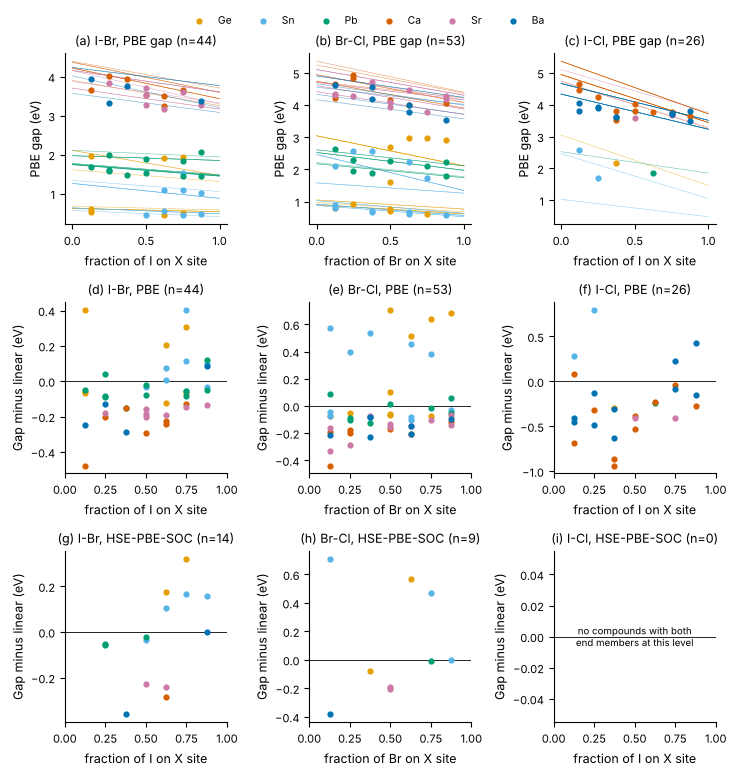

numbers.json now holds 244 numbers


In [31]:
# fig20: gap versus halide fraction (row 1) and deviation from linear interpolation (row 2) at PBE and HSE-PBE-SOC
plot_levels = ["PBE", "HSE-PBE-SOC"]
fig, axes = plt.subplots(3, 3, figsize=(7.4, 7.6))
for column, (heavy, light) in enumerate(HALIDE_PAIRS):
    pair_name = heavy + "-" + light
    # Row 1: PBE gap against fraction, with end members joined by straight lines
    ax = axes[0, column]
    part = bowing_complete[(bowing_complete["pair"] == pair_name) & (bowing_complete["level"] == "PBE")]
    for b_element in B_ELEMENTS:
        sub = part[part["B"] == b_element]
        ax.scatter(sub["x_heavy"], sub["gap_eV"], s=12, color=COLOR_B[b_element], label=b_element, zorder=3)
        for row in sub.itertuples():
            ax.plot([0, 1], [row.end_light_eV, row.end_heavy_eV], color=COLOR_B[b_element], linewidth=0.4, alpha=0.6)
    ax.set_xlabel("fraction of %s on X site" % heavy)
    ax.set_ylabel("PBE gap (eV)")
    ax.set_title("%s, PBE gap (n=%d)" % (pair_name, len(part)))
    panel_label(ax, "abc"[column])
    # Rows 2 and 3: deviation at PBE and at HSE-PBE-SOC
    for row_index, level in enumerate(plot_levels, start=1):
        ax = axes[row_index, column]
        part = bowing_complete[(bowing_complete["pair"] == pair_name) & (bowing_complete["level"] == level)]
        for b_element in B_ELEMENTS:
            sub = part[part["B"] == b_element]
            ax.scatter(sub["x_heavy"], sub["deviation_eV"], s=12, color=COLOR_B[b_element], label=b_element, zorder=3)
        flagged = part[part["flag_any_outlier"]]
        ax.scatter(flagged["x_heavy"], flagged["deviation_eV"], s=40, facecolors="none", edgecolors="black", linewidths=0.8)
        ax.axhline(0, color="black", linewidth=0.6)
        ax.set_xlim(0, 1)
        ax.set_xlabel("fraction of %s on X site" % heavy)
        ax.set_ylabel("Gap minus linear (eV)")
        ax.set_title("%s, %s (n=%d)" % (pair_name, level, len(part)))
        if len(part) == 0:
            ax.text(0.5, 0.5, "no compounds with both\nend members at this level", ha="center", va="center",
                    transform=ax.transAxes, fontsize=7)
        panel_label(ax, "defghi"[(row_index - 1) * 3 + column])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
save_fig(fig, "fig20_bowing")
write_numbers()

## Stage 3: variance decomposition

Question: what fraction of the spread in band gaps goes with the A cation, the halide, the B element and the B group,
taken one label at a time? The one-way fractions overlap (they are not additive) and the dataset is not balanced, so
an additive model R2 is reported next to them.

In [32]:
# Labels: A, X and B use the main (largest-fraction) element on each site; "B group (g2_frac)" is the strict group
# from g2_frac (Group 14 / mixed B / Group 2), never the idxmax label.
VARIANCE_LABELS = {"A site (main)": "A_main", "X site (main)": "X_main", "B element (main)": "B_main",
                   "B group (g2_frac)": "strict_group"}


def additive_r2(table, target_column):
    """In-sample R2 of an additive model with one-hot A_main + X_main + B_main (labels with one level drop out)."""
    design = pd.get_dummies(table[["A_main", "X_main", "B_main"]], drop_first=True).astype(float)
    model = LinearRegression().fit(design, table[target_column])
    return r2_score(table[target_column], model.predict(design)), design.shape[1]


def fraction_linear_r2(table, target_column):
    """In-sample R2 of a linear model on composition fractions (references Cs, Pb, Cl dropped)."""
    columns = ["frac_K", "frac_Rb", "frac_Ma", "frac_Fa", "frac_Br", "frac_I", "frac_Ge", "frac_Sn",
               "frac_Ca", "frac_Sr", "frac_Ba"]
    columns = [c for c in columns if table[c].std() > 0]
    model = LinearRegression().fit(table[columns], table[target_column])
    return r2_score(table[target_column], model.predict(table[columns]))


variance_rows = []
SUBSETS = {"all": features, "strict Group 14": features[features["strict_group"] == "Group 14"],
           "strict Group 2": features[features["strict_group"] == "Group 2"]}
for level in LEVELS:
    for subset_name, subset in SUBSETS.items():
        part = subset.dropna(subset=[GAP_COL[level]])
        row = {"level": level, "subset": subset_name, "n": len(part)}
        for label_name, column in VARIANCE_LABELS.items():
            if part[column].nunique() > 1:
                row[label_name] = eta_squared(part[GAP_COL[level]], part[column])
            else:
                row[label_name] = np.nan
        row["sum of one-way fractions"] = np.nansum([row[k] for k in VARIANCE_LABELS])
        row["additive one-hot A+X+B R2 (in-sample)"], row["n_parameters_one_hot"] = additive_r2(part, GAP_COL[level])
        row["linear on fractions R2 (in-sample)"] = fraction_linear_r2(part, GAP_COL[level])
        variance_rows.append(row)
variance_table = pd.DataFrame(variance_rows).round(3)
save_table(variance_table, "fig09_variance_explained")
for row in variance_table.to_dict("records"):
    for key in list(VARIANCE_LABELS) + ["additive one-hot A+X+B R2 (in-sample)", "linear on fractions R2 (in-sample)"]:
        name = "eta2_%s_%s_%s" % (row["level"], row["subset"].replace(" ", "_"), key.split(" (")[0].replace(" ", "_"))
        record(name, row[key], "stage 3", "n=%d" % row["n"])
variance_table

saved table fig09_variance_explained.csv shape (12, 11)


,level,subset,n,A site (main),X site (main),B element (main),B group (g2_frac),sum of one-way fractions,additive one-hot A+X+B R2 (in-sample),n_parameters_one_hot,linear on fractions R2 (in-sample)
0,PBE,all,488,0.015,0.080,0.713,0.715,1.524,0.813,11,0.922
1,PBE,strict Group 14,178,0.417,0.137,0.221,NaN,0.775,0.750,8,0.792
2,PBE,strict Group 2,187,0.072,0.634,0.054,NaN,0.759,0.724,8,0.868
3,HSErel,all,299,0.036,0.157,0.565,0.591,1.350,0.762,11,0.851
4,HSErel,strict Group 14,88,0.451,0.109,0.066,NaN,0.627,0.630,8,0.631
5,HSErel,strict Group 2,94,0.072,0.772,0.064,NaN,0.907,0.877,8,0.922
6,HSErel_SOC,all,282,0.039,0.160,0.540,0.616,1.355,0.748,11,0.861
7,HSErel_SOC,strict Group 14,82,0.599,0.102,0.005,NaN,0.706,0.742,8,0.733
8,HSErel_SOC,strict Group 2,89,0.078,0.792,0.050,NaN,0.919,0.887,8,0.935
9,HSE-PBE-SOC,all,244,0.015,0.125,0.659,0.731,1.531,0.788,11,0.948


In [33]:
# Balance of the dataset: how many HSE-PBE-SOC compounds per main label
balance = []
hps_rows = features.dropna(subset=[G_HPS])
for label_name, column in VARIANCE_LABELS.items():
    counts = hps_rows[column].value_counts()
    balance.append({"label": label_name, "counts (HSE-PBE-SOC rows)": ", ".join("%s=%d" % (k, v) for k, v in counts.items())})
balance_table = pd.DataFrame(balance)
save_table(balance_table, "stage3_label_balance")
print(balance_table.to_string(index=False))

saved table stage3_label_balance.csv shape (4, 2)
            label                counts (HSE-PBE-SOC rows)
    A site (main)         Ma=69, Rb=51, K=49, Cs=43, Fa=32
    X site (main)                       I=87, Br=85, Cl=72
 B element (main) Pb=51, Ge=45, Sn=41, Ca=39, Ba=35, Sr=33
B group (g2_frac)      mixed B=91, Group 2=77, Group 14=76


saved fig09_variance_explained.png


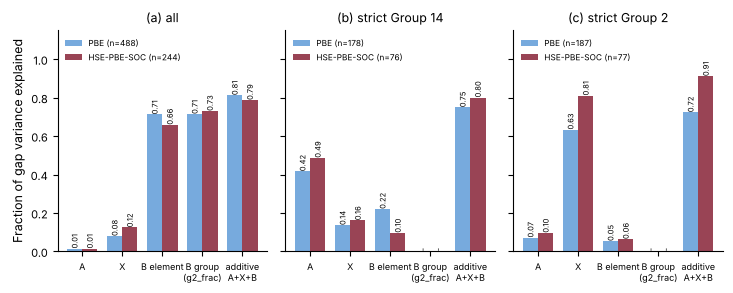

In [34]:
# fig09: one-way variance fractions and additive R2 for the HSE-PBE-SOC gap (also PBE for comparison)
bar_labels = list(VARIANCE_LABELS) + ["additive one-hot A+X+B R2 (in-sample)"]
short_labels = ["A", "X", "B element", "B group\n(g2_frac)", "additive\nA+X+B"]
fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.0), sharey=True)
for ax, subset_name, letter in zip(axes, SUBSETS, "abc"):
    width = 0.38
    for offset, level in [(-width / 2, "PBE"), (width / 2, "HSE-PBE-SOC")]:
        row = variance_table[(variance_table["level"] == level) & (variance_table["subset"] == subset_name)].iloc[0]
        values = [row[k] for k in bar_labels]
        positions = np.arange(len(bar_labels)) + offset
        ax.bar(positions, np.nan_to_num(values), width=width, color=COLOR_LEVEL[level], label="%s (n=%d)" % (level, row["n"]))
        for position, value in zip(positions, values):
            ax.text(position, (0 if np.isnan(value) else value) + 0.01, "-" if np.isnan(value) else "%.2f" % value,
                    ha="center", fontsize=5.5, rotation=90)
    ax.set_xticks(np.arange(len(bar_labels)))
    ax.set_xticklabels(short_labels, fontsize=6.5)
    ax.set_ylim(0, 1.15)
    ax.set_title(subset_name)
    ax.legend(frameon=False, fontsize=6, loc="upper left")
    panel_label(ax, letter)
axes[0].set_ylabel("Fraction of gap variance explained")
fig.tight_layout()
save_fig(fig, "fig09_variance_explained")

In [35]:
# Comparison with the earlier (contaminated) values from CLAUDE.md section 9 item 3: HSE-PBE-SOC, all 244
earlier_variance = {"A site (main)": 0.01, "X site (main)": 0.12, "B element (main)": 0.66, "B group (g2_frac)": 0.63}
row = variance_table[(variance_table["level"] == "HSE-PBE-SOC") & (variance_table["subset"] == "all")].iloc[0]
comparison = pd.DataFrame([{"label": k, "this run": row[k], "earlier (idxmax-defined group)": v, "difference": row[k] - v}
                           for k, v in earlier_variance.items()]).round(3)
save_table(comparison, "stage3_compare_section9")
write_numbers()
comparison

saved table stage3_compare_section9.csv shape (4, 4)
numbers.json now holds 316 numbers


,label,this run,earlier (idxmax-defined group),difference
0,A site (main),0.015,0.01,0.005
1,X site (main),0.125,0.12,0.005
2,B element (main),0.659,0.66,-0.001
3,B group (g2_frac),0.731,0.63,0.101


## Stage 4: interpretable composition models inside strict Group 14

Question: inside strict Group 14 (no Ca, Sr or Ba at all, g2_frac == 0), how much of the HSE-PBE-SOC gap does a
linear model on composition fractions explain under honest grouped cross-validation, and what are its coefficients?
We also test whether the deviation-of-cubicity columns add anything beyond an "organic A-site" fraction.

In [36]:
# Data for this stage: strict Group 14 compounds with an HSE-PBE-SOC gap
g14 = features[(features["g2_frac"] == 0) & features[G_HPS].notna()].copy().reset_index(drop=True)
g14_groups = g14["group_key"].values
print("strict Group 14 compounds with HSE-PBE-SOC gap:", len(g14))
print("groups (main A + main B + main X):", g14["group_key"].nunique())
print("largest groups:", g14["group_key"].value_counts().head(5).to_dict())
assert g14["g2_frac"].max() == 0
record("g14_n", len(g14), "stage 4")
record("g14_n_groups", g14["group_key"].nunique(), "stage 4")

# Linear model features: composition fractions. References: Cs (A), Cl (X), Pb (B).
FRAC_FEATURES = ["frac_K", "frac_Rb", "frac_Ma", "frac_Fa", "frac_Br", "frac_I", "frac_Ge", "frac_Sn"]
FRAC_NAMES = {"frac_K": "K", "frac_Rb": "Rb", "frac_Ma": "MA", "frac_Fa": "FA", "frac_Br": "Br", "frac_I": "I",
              "frac_Ge": "Ge", "frac_Sn": "Sn"}
X_g14 = g14[FRAC_FEATURES].values
y_g14 = g14[G_HPS].values

GROUPED_CV = GroupKFold(n_splits=5)
RANDOM_CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Show the fold sizes of the grouped split (test rows per fold)
fold_sizes = [len(test) for _, test in GROUPED_CV.split(X_g14, y_g14, g14_groups)]
print("GroupKFold test-fold sizes:", fold_sizes)

strict Group 14 compounds with HSE-PBE-SOC gap: 76
groups (main A + main B + main X): 43
largest groups: {'Ma-Pb-Br': 4, 'Ma-Sn-I': 4, 'Fa-Ge-I': 3, 'Ma-Pb-I': 3, 'Ma-Sn-Cl': 3}
GroupKFold test-fold sizes: [16, 15, 15, 15, 15]


In [37]:
# Models compared with random KFold and GroupKFold (5 folds each)
def poly_ridge(alpha):
    return Pipeline([("products", PolynomialFeatures(degree=2, include_bias=False)),
                     ("scale", StandardScaler()), ("ridge", Ridge(alpha=alpha))])


RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0]
stage4_models = {"mean baseline": DummyRegressor(strategy="mean"), "linear (fractions)": LinearRegression()}
for alpha in RIDGE_ALPHAS:
    stage4_models["products Ridge alpha=%g" % alpha] = poly_ridge(alpha)

cv_rows = []
oof_predictions = {}
for model_name, model in stage4_models.items():
    for cv_name, splitter in [("random KFold", RANDOM_CV), ("GroupKFold", GROUPED_CV)]:
        scores = cv_scores(model, X_g14, y_g14, splitter, g14_groups)
        oof_predictions[(model_name, cv_name)] = scores["predictions"]
        cv_rows.append({"model": model_name, "cv": cv_name, "R2_pooled": scores["R2"],
                        "R2_mean_of_folds": scores["R2_fold_mean"], "MAE_eV": scores["MAE"], "n": len(y_g14)})


# Nested grouped CV: alpha chosen by an inner GroupKFold(4) on the training folds only (honest)
def nested_grouped_predictions(X, y, groups):
    predictions = np.full(len(y), np.nan)
    chosen_alphas = []
    for train_index, test_index in GROUPED_CV.split(X, y, groups):
        search = GridSearchCV(poly_ridge(1.0), {"ridge__alpha": RIDGE_ALPHAS}, cv=GroupKFold(n_splits=4), scoring="r2")
        search.fit(X[train_index], y[train_index], groups=groups[train_index])
        chosen_alphas.append(search.best_params_["ridge__alpha"])
        predictions[test_index] = search.predict(X[test_index])
    return predictions, chosen_alphas


nested_predictions, nested_alphas = nested_grouped_predictions(X_g14, y_g14, g14_groups)
oof_predictions[("products Ridge, nested alpha", "GroupKFold")] = nested_predictions
cv_rows.append({"model": "products Ridge, nested alpha", "cv": "GroupKFold", "R2_pooled": r2_score(y_g14, nested_predictions),
                "R2_mean_of_folds": np.nan, "MAE_eV": mae(y_g14, nested_predictions), "n": len(y_g14)})
print("alpha chosen in each outer fold (nested):", nested_alphas)
stage4_cv = pd.DataFrame(cv_rows).round(3)
save_table(stage4_cv, "fig12_random_vs_grouped")
for row in stage4_cv.itertuples():
    record("g14_R2_%s_%s" % (row.model.replace(" ", "_"), row.cv.replace(" ", "_")), row.R2_pooled, "stage 4",
           "pooled out-of-fold R2, n=%d" % row.n)
    record("g14_MAE_%s_%s" % (row.model.replace(" ", "_"), row.cv.replace(" ", "_")), row.MAE_eV, "stage 4")
stage4_cv

alpha chosen in each outer fold (nested): [10.0, 10.0, 10.0, 10.0, 10.0]
saved table fig12_random_vs_grouped.csv shape (13, 6)


,model,cv,R2_pooled,R2_mean_of_folds,MAE_eV,n
0,mean baseline,random KFold,-0.061,-0.155,0.577,76
1,mean baseline,GroupKFold,-0.036,-0.104,0.581,76
2,linear (fractions),random KFold,0.739,0.709,0.274,76
3,linear (fractions),GroupKFold,0.738,0.729,0.285,76
4,products Ridge alpha=0.1,random KFold,0.924,0.905,0.146,76
5,products Ridge alpha=0.1,GroupKFold,0.794,0.772,0.242,76
6,products Ridge alpha=1,random KFold,0.912,0.894,0.153,76
7,products Ridge alpha=1,GroupKFold,0.866,0.845,0.216,76
8,products Ridge alpha=10,random KFold,0.857,0.839,0.192,76
9,products Ridge alpha=10,GroupKFold,0.864,0.848,0.213,76


In [38]:
# Compare with CLAUDE.md section 9 item 4 (earlier session; random / grouped R2)
earlier_stage4 = {"linear (fractions)": (0.74, 0.74), "products Ridge alpha=0.1": (0.92, 0.76),
                  "products Ridge alpha=1": (0.91, 0.80), "products Ridge alpha=10": (0.86, 0.82),
                  "products Ridge alpha=100": (0.66, 0.65)}
compare_rows = []
for model_name, (earlier_random, earlier_grouped) in earlier_stage4.items():
    this_random = stage4_cv[(stage4_cv["model"] == model_name) & (stage4_cv["cv"] == "random KFold")]["R2_pooled"].iloc[0]
    this_grouped = stage4_cv[(stage4_cv["model"] == model_name) & (stage4_cv["cv"] == "GroupKFold")]["R2_pooled"].iloc[0]
    compare_rows.append({"model": model_name, "random R2 this run": this_random, "random R2 earlier": earlier_random,
                         "grouped R2 this run": this_grouped, "grouped R2 earlier": earlier_grouped,
                         "grouped difference": this_grouped - earlier_grouped})
stage4_compare = pd.DataFrame(compare_rows).round(3)
save_table(stage4_compare, "stage4_compare_section9")
stage4_compare

saved table stage4_compare_section9.csv shape (5, 6)


,model,random R2 this run,random R2 earlier,grouped R2 this run,grouped R2 earlier,grouped difference
0,linear (fractions),0.739,0.74,0.738,0.74,-0.002
1,products Ridge alpha=0.1,0.924,0.92,0.794,0.76,0.034
2,products Ridge alpha=1,0.912,0.91,0.866,0.80,0.066
3,products Ridge alpha=10,0.857,0.86,0.864,0.82,0.044
4,products Ridge alpha=100,0.658,0.66,0.685,0.65,0.035


saved fig12_random_vs_grouped.png


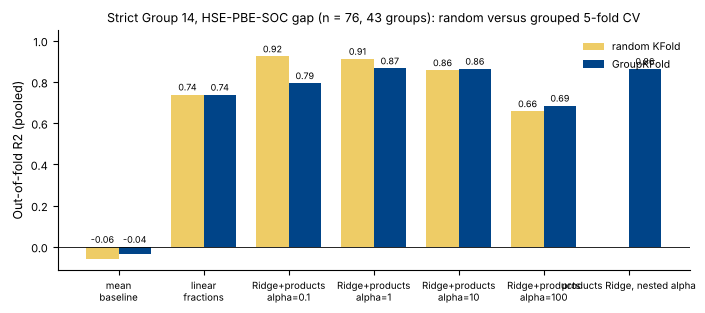

saved fig10_composition_parity.png


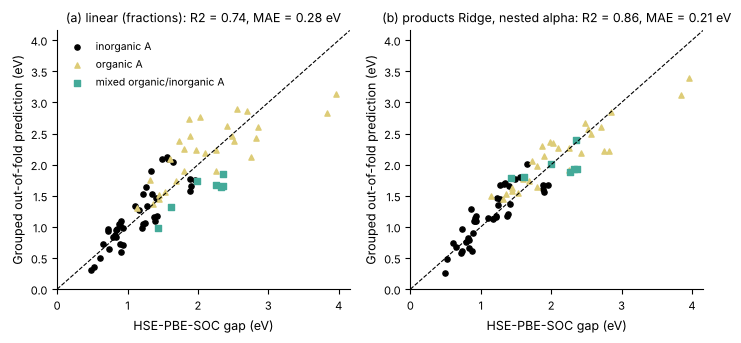

saved table fig10_composition_parity.csv shape (76, 5)


In [39]:
# fig12: random versus grouped R2 for every model; fig10: grouped out-of-fold parity plots
fig, ax = plt.subplots(figsize=(7.2, 3.2))
model_order = list(stage4_models) + ["products Ridge, nested alpha"]
width = 0.38
for offset, cv_name in [(-width / 2, "random KFold"), (width / 2, "GroupKFold")]:
    values = []
    for model_name in model_order:
        match = stage4_cv[(stage4_cv["model"] == model_name) & (stage4_cv["cv"] == cv_name)]
        values.append(match["R2_pooled"].iloc[0] if len(match) else np.nan)
    positions = np.arange(len(model_order)) + offset
    ax.bar(positions, np.nan_to_num(values), width=width, color=COLOR_CV[cv_name], label=cv_name)
    for position, value in zip(positions, values):
        if np.isfinite(value):
            ax.text(position, max(value, 0) + 0.02, "%.2f" % value, ha="center", fontsize=6.5)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(np.arange(len(model_order)))
ax.set_xticklabels([m.replace("products Ridge ", "Ridge+products\n").replace("linear (fractions)", "linear\nfractions")
                    .replace("mean baseline", "mean\nbaseline") for m in model_order], fontsize=7)
ax.set_ylabel("Out-of-fold R2 (pooled)")
ax.set_ylim(min(-0.1, np.nanmin(stage4_cv["R2_pooled"]) - 0.05), 1.05)
ax.set_title("Strict Group 14, HSE-PBE-SOC gap (n = %d, %d groups): random versus grouped 5-fold CV"
             % (len(g14), g14["group_key"].nunique()))
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig12_random_vs_grouped")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.5))
for ax, model_name, letter in zip(axes, ["linear (fractions)", "products Ridge, nested alpha"], "ab"):
    predictions = oof_predictions[(model_name, "GroupKFold")]
    for a_type in COLOR_ATYPE:
        mask = (g14["A_type"] == a_type).values
        ax.scatter(y_g14[mask], predictions[mask], s=14, color=COLOR_ATYPE[a_type], marker=MARKER_ATYPE[a_type], label=a_type)
    limits = [0, max(y_g14.max(), np.nanmax(predictions)) + 0.2]
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel("HSE-PBE-SOC gap (eV)")
    ax.set_ylabel("Grouped out-of-fold prediction (eV)")
    ax.set_title("%s: R2 = %.2f, MAE = %.2f eV" % (model_name, r2_score(y_g14, predictions), mae(y_g14, predictions)))
    panel_label(ax, letter)
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig10_composition_parity")
parity_table = g14[["Formula", "A_type", G_HPS]].copy()
parity_table["pred_linear_grouped"] = oof_predictions[("linear (fractions)", "GroupKFold")]
parity_table["pred_ridge_nested_grouped"] = nested_predictions
save_table(parity_table.round(4), "fig10_composition_parity")

### Linear coefficients with bootstrap intervals
Each coefficient is the change of the HSE-PBE-SOC gap (eV) when the site is fully replaced, relative to the reference
compound CsPbCl3 (the intercept is the model gap of a CsPbCl3-like compound). Intervals: 500 bootstrap resamples of
the rows (95 percent percentile interval). Because rows of the same group are correlated, a second interval resamples
whole groups (cluster bootstrap); it is usually wider.

In [40]:
def bootstrap_coefficients(X, y, groups, n_resamples, by_group, seed):
    rng = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    collected = []
    for _ in range(n_resamples):
        if by_group:
            chosen_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
            index = np.concatenate([np.where(groups == g)[0] for g in chosen_groups])
        else:
            index = rng.integers(0, len(y), size=len(y))
        model = LinearRegression().fit(X[index], y[index])
        collected.append(np.concatenate([[model.intercept_], model.coef_]))
    return np.array(collected)


full_linear = LinearRegression().fit(X_g14, y_g14)
row_boot = bootstrap_coefficients(X_g14, y_g14, g14_groups, N_BOOTSTRAP, by_group=False, seed=RANDOM_STATE)
group_boot = bootstrap_coefficients(X_g14, y_g14, g14_groups, N_BOOTSTRAP, by_group=True, seed=RANDOM_STATE)
coefficient_names = ["intercept (CsPbCl3-like)"] + [FRAC_NAMES[c] for c in FRAC_FEATURES]
earlier_coefficients = {"intercept (CsPbCl3-like)": 1.78, "K": -0.11, "Rb": -0.11, "MA": 0.82, "FA": 1.19,
                        "Br": -0.46, "I": -0.96, "Ge": 0.22, "Sn": -0.32}
coefficient_table = pd.DataFrame({
    "term": coefficient_names,
    "coefficient_eV": np.concatenate([[full_linear.intercept_], full_linear.coef_]),
    "row_boot_low_eV": np.percentile(row_boot, 2.5, axis=0),
    "row_boot_high_eV": np.percentile(row_boot, 97.5, axis=0),
    "group_boot_low_eV": np.percentile(group_boot, 2.5, axis=0),
    "group_boot_high_eV": np.percentile(group_boot, 97.5, axis=0),
})
coefficient_table["row_interval_includes_zero"] = (coefficient_table["row_boot_low_eV"] <= 0) & (coefficient_table["row_boot_high_eV"] >= 0)
coefficient_table["group_interval_includes_zero"] = (coefficient_table["group_boot_low_eV"] <= 0) & (coefficient_table["group_boot_high_eV"] >= 0)
coefficient_table["earlier_eV"] = coefficient_table["term"].map(earlier_coefficients)
coefficient_table["difference_vs_earlier"] = coefficient_table["coefficient_eV"] - coefficient_table["earlier_eV"]
coefficient_table = coefficient_table.round(3)
save_table(coefficient_table, "fig11_coefficients")
print("in-sample R2 of the full linear fit: %.3f" % r2_score(y_g14, full_linear.predict(X_g14)))
for row in coefficient_table.itertuples():
    key = row.term.split(" ")[0]
    record("g14_coef_" + key, row.coefficient_eV, "stage 4", "linear fractions, n=%d" % len(y_g14))
    record("g14_coef_%s_rowboot_low" % key, row.row_boot_low_eV, "stage 4")
    record("g14_coef_%s_rowboot_high" % key, row.row_boot_high_eV, "stage 4")
    record("g14_coef_%s_groupboot_low" % key, row.group_boot_low_eV, "stage 4")
    record("g14_coef_%s_groupboot_high" % key, row.group_boot_high_eV, "stage 4")
coefficient_table

saved table fig11_coefficients.csv shape (9, 10)
in-sample R2 of the full linear fit: 0.830


,term,coefficient_eV,row_boot_low_eV,row_boot_high_eV,group_boot_low_eV,group_boot_high_eV,row_interval_includes_zero,group_interval_includes_zero,earlier_eV,difference_vs_earlier
0,intercept (CsPbCl3-like),1.777,1.623,1.939,1.568,1.963,False,False,1.78,-0.003
1,K,-0.112,-0.315,0.071,-0.284,0.111,True,True,-0.11,-0.002
2,Rb,-0.106,-0.264,0.051,-0.282,0.122,True,True,-0.11,0.004
3,MA,0.820,0.667,0.996,0.614,0.997,False,False,0.82,-0.000
4,FA,1.190,0.893,1.540,0.797,1.653,False,False,1.19,0.000
5,Br,-0.464,-0.668,-0.288,-0.679,-0.216,False,False,-0.46,-0.004
6,I,-0.958,-1.143,-0.793,-1.183,-0.743,False,False,-0.96,0.002
7,Ge,0.223,0.028,0.429,-0.043,0.474,False,True,0.22,0.003
8,Sn,-0.321,-0.474,-0.158,-0.502,-0.135,False,False,-0.32,-0.001


saved fig11_coefficients.png


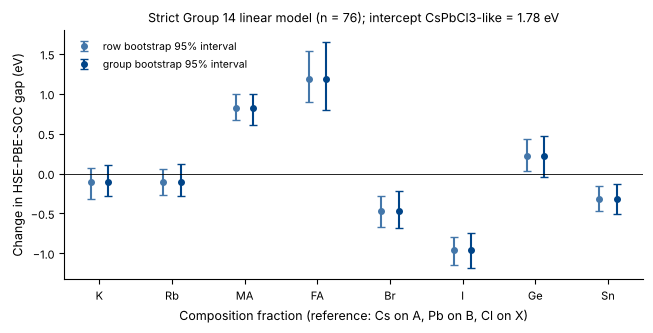

In [41]:
# fig11: coefficients with 95 percent bootstrap intervals (row and group bootstrap)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
terms = coefficient_table["term"].iloc[1:].tolist()
positions = np.arange(len(terms))
coefs = coefficient_table["coefficient_eV"].iloc[1:].values
for offset, low_col, high_col, colour, label in [(-0.12, "row_boot_low_eV", "row_boot_high_eV", COLOR_MODEL["Linear"], "row bootstrap 95% interval"),
                                                 (0.12, "group_boot_low_eV", "group_boot_high_eV", COLOR_CV["GroupKFold"], "group bootstrap 95% interval")]:
    low = coefficient_table[low_col].iloc[1:].values
    high = coefficient_table[high_col].iloc[1:].values
    ax.errorbar(positions + offset, coefs, yerr=[coefs - low, high - coefs], fmt="o", color=colour, capsize=3,
                markersize=4, label=label)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(positions)
ax.set_xticklabels(terms)
ax.set_xlabel("Composition fraction (reference: Cs on A, Pb on B, Cl on X)")
ax.set_ylabel("Change in HSE-PBE-SOC gap (eV)")
ax.set_title("Strict Group 14 linear model (n = %d); intercept CsPbCl3-like = %.2f eV"
             % (len(y_g14), coefficient_table["coefficient_eV"].iloc[0]))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig11_coefficients")

### Deviation of cubicity versus organic A-site
The five deviation-of-cubicity columns come from the PBE-relaxed structures (PBE sheet). We compare grouped R2 for
four feature sets, all on the same rows: B+X fractions only; + organic fraction (MA+FA); + the five deviation columns;
+ both. Organic fraction and deviation are strongly associated in this dataset, so no causal or "mediating" claim is
made from this comparison.

In [42]:
g14_dev = g14.dropna(subset=DEV_COLS).reset_index(drop=True)
print("strict Group 14 rows with all deviation values:", len(g14_dev), "of", len(g14),
      "(missing:", g14.loc[g14[DEV_COLS].isna().any(axis=1), "Formula"].tolist(), ")")
BX_FEATURES = ["frac_Br", "frac_I", "frac_Ge", "frac_Sn"]
DEVIATION_SETS = {"B+X only": BX_FEATURES, "+ organic": BX_FEATURES + ["organic_frac"],
                  "+ deviation": BX_FEATURES + DEV_COLS, "+ both": BX_FEATURES + ["organic_frac"] + DEV_COLS,
                  "all fractions": FRAC_FEATURES, "all fractions + deviation": FRAC_FEATURES + DEV_COLS}
y_dev = g14_dev[G_HPS].values
dev_groups = g14_dev["group_key"].values
deviation_rows = []
for set_name, columns in DEVIATION_SETS.items():
    for cv_name, splitter in [("random KFold", RANDOM_CV), ("GroupKFold", GROUPED_CV)]:
        scores = cv_scores(LinearRegression(), g14_dev[columns].values, y_dev, splitter, dev_groups)
        deviation_rows.append({"feature set": set_name, "cv": cv_name, "R2_pooled": scores["R2"], "MAE_eV": scores["MAE"],
                               "n": len(y_dev), "n_features": len(columns)})
deviation_table = pd.DataFrame(deviation_rows).round(3)
save_table(deviation_table, "fig14_organic_vs_deviation")
for row in deviation_table.itertuples():
    record("g14_dev_R2_%s_%s" % (row._1.replace(" ", "_").replace("+", "plus"), row.cv.replace(" ", "_")), row.R2_pooled,
           "stage 4", "linear, n=%d" % row.n)
deviation_table

strict Group 14 rows with all deviation values: 75 of 76 (missing: ['RbGeBr_1.125Cl_1.875'] )
saved table fig14_organic_vs_deviation.csv shape (12, 6)


,feature set,cv,R2_pooled,MAE_eV,n,n_features
0,B+X only,random KFold,0.205,0.533,75,4
1,B+X only,GroupKFold,0.179,0.553,75,4
2,+ organic,random KFold,0.735,0.287,75,5
3,+ organic,GroupKFold,0.773,0.275,75,5
4,+ deviation,random KFold,0.796,0.243,75,9
5,+ deviation,GroupKFold,0.786,0.263,75,9
6,+ both,random KFold,0.833,0.184,75,10
7,+ both,GroupKFold,0.822,0.205,75,10
8,all fractions,random KFold,0.762,0.267,75,8
9,all fractions,GroupKFold,0.780,0.265,75,8


In [43]:
# Coefficient changes when the deviation columns are added (in-sample fits on the same rows)
fit_without = LinearRegression().fit(g14_dev[FRAC_FEATURES], y_dev)
fit_with = LinearRegression().fit(g14_dev[FRAC_FEATURES + DEV_COLS], y_dev)
coefficient_change = pd.DataFrame({
    "term": [FRAC_NAMES[c] for c in FRAC_FEATURES] + DEV_COLS,
    "without_deviation_eV": list(fit_without.coef_) + [np.nan] * len(DEV_COLS),
    "with_deviation_eV": list(fit_with.coef_),
}).round(3)
save_table(coefficient_change, "stage4_coefficients_with_deviation")
for row in coefficient_change.itertuples():
    record("g14_coef_with_dev_" + row.term, row.with_deviation_eV, "stage 4", "n=%d" % len(y_dev))
# How closely do organic fraction and deviation go together?
association_rows = []
for column in DEV_COLS:
    association_rows.append({"deviation column": column, "pearson_r_with_organic_frac": g14_dev[column].corr(g14_dev["organic_frac"]),
                             "max_inorganic_A": g14_dev.loc[g14_dev["A_type"] == "inorganic A", column].max(),
                             "median_organic_A": g14_dev.loc[g14_dev["A_type"] == "organic A", column].median(),
                             "median_mixed_A": g14_dev.loc[g14_dev["A_type"] == "mixed organic/inorganic A", column].median()})
association = pd.DataFrame(association_rows).round(4)
save_table(association, "stage4_organic_deviation_association")
print(coefficient_change.to_string(index=False))
association

saved table stage4_coefficients_with_deviation.csv shape (13, 3)
saved table stage4_organic_deviation_association.csv shape (5, 5)
     term  without_deviation_eV  with_deviation_eV
        K                -0.111             -0.078
       Rb                -0.083             -0.076
       MA                 0.821              0.254
       FA                 1.188             -0.370
       Br                -0.472             -0.497
        I                -0.972             -0.850
       Ge                 0.239             -0.153
       Sn                -0.321             -0.430
    dev_b                   NaN              6.010
    dev_c                   NaN              4.796
dev_alpha                   NaN              3.610
 dev_beta                   NaN             11.912
dev_gamma                   NaN              8.491


,deviation column,pearson_r_with_organic_frac,max_inorganic_A,median_organic_A,median_mixed_A
0,dev_b,0.5652,0.0213,0.0307,0.0465
1,dev_c,0.5227,0.0114,0.0232,0.0450
2,dev_alpha,0.4300,0.0002,0.0139,0.0688
3,dev_beta,0.5440,0.0002,0.0165,0.0000
4,dev_gamma,0.5077,0.0000,0.0025,0.0000


saved fig14_organic_vs_deviation.png


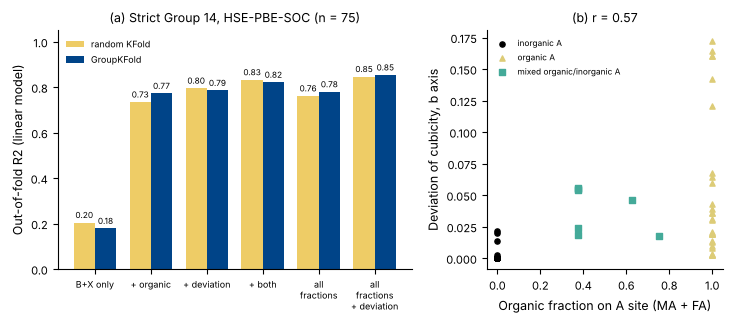

In [44]:
# fig14: (a) grouped and random R2 for the deviation / organic feature sets, (b) organic fraction vs deviation (b axis)
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
set_order = list(DEVIATION_SETS)
for offset, cv_name in [(-0.19, "random KFold"), (0.19, "GroupKFold")]:
    values = [deviation_table[(deviation_table["feature set"] == s) & (deviation_table["cv"] == cv_name)]["R2_pooled"].iloc[0] for s in set_order]
    positions = np.arange(len(set_order)) + offset
    ax.bar(positions, values, width=0.38, color=COLOR_CV[cv_name], label=cv_name)
    for position, value in zip(positions, values):
        ax.text(position, max(value, 0) + 0.02, "%.2f" % value, ha="center", fontsize=6)
ax.set_xticks(np.arange(len(set_order)))
ax.set_xticklabels([s.replace(" + ", "\n+ ").replace("all fractions", "all\nfractions") for s in set_order], fontsize=6.5)
ax.set_ylabel("Out-of-fold R2 (linear model)")
ax.set_ylim(min(0, deviation_table["R2_pooled"].min() - 0.05), 1.05)
ax.set_title("Strict Group 14, HSE-PBE-SOC (n = %d)" % len(y_dev))
ax.legend(frameon=False, loc="upper left", fontsize=6.5)
panel_label(ax, "a")
ax = axes[1]
for a_type in COLOR_ATYPE:
    part = g14_dev[g14_dev["A_type"] == a_type]
    ax.scatter(part["organic_frac"], part["dev_b"], s=14, color=COLOR_ATYPE[a_type], marker=MARKER_ATYPE[a_type], label=a_type)
ax.set_xlabel("Organic fraction on A site (MA + FA)")
ax.set_ylabel("Deviation of cubicity, b axis")
ax.set_title("r = %.2f" % g14_dev["organic_frac"].corr(g14_dev["dev_b"]))
ax.legend(frameon=False, fontsize=6)
panel_label(ax, "b")
fig.tight_layout()
save_fig(fig, "fig14_organic_vs_deviation")

saved fig13_deviation_residuals.png


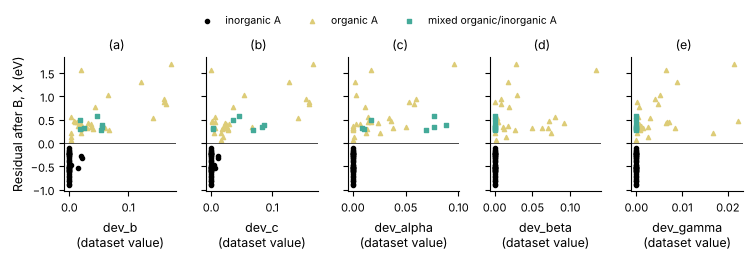

saved table fig13_deviation_residuals.csv shape (75, 9)
saved table fig13_residual_summary.csv shape (5, 5)
numbers.json now holds 419 numbers


,A_type,near_zero_dev,size,mean,std
0,inorganic A,False,3,-0.378,0.141
1,inorganic A,True,37,-0.471,0.224
2,mixed organic/inorganic A,False,7,0.385,0.109
3,organic A,False,22,0.635,0.437
4,organic A,True,6,0.313,0.202


In [45]:
# fig13: residual after removing B and X effects (in-sample linear fit on Br, I, Ge, Sn) versus each deviation column
bx_fit = LinearRegression().fit(g14_dev[BX_FEATURES], y_dev)
g14_dev["residual_after_BX"] = y_dev - bx_fit.predict(g14_dev[BX_FEATURES])
fig, axes = plt.subplots(1, 5, figsize=(7.6, 2.4), sharey=True)
for ax, column, letter in zip(axes, DEV_COLS, "abcde"):
    for a_type in COLOR_ATYPE:
        part = g14_dev[g14_dev["A_type"] == a_type]
        ax.scatter(part[column], part["residual_after_BX"], s=9, color=COLOR_ATYPE[a_type], marker=MARKER_ATYPE[a_type], label=a_type)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel(column + "\n(dataset value)")
    ax.set_title(" ")
    panel_label(ax, letter)
axes[0].set_ylabel("Residual after B, X (eV)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
save_fig(fig, "fig13_deviation_residuals")
residual_summary = g14_dev.assign(near_zero_dev=g14_dev["dev_b"] < 0.01).groupby(["A_type", "near_zero_dev"])["residual_after_BX"].agg(["size", "mean", "std"]).round(3).reset_index()
save_table(g14_dev[["Formula", "A_type", "organic_frac"] + DEV_COLS + ["residual_after_BX"]].round(4), "fig13_deviation_residuals")
save_table(residual_summary, "fig13_residual_summary")
for row in residual_summary.itertuples():
    record("g14_residual_mean_%s_devb_below_0p01_%s" % (row.A_type.replace(" ", "_").replace("/", "_"), row.near_zero_dev), row.mean, "stage 4", "n=%d" % row.size)
write_numbers()
residual_summary